# Servicio de IA de TrazaRed HUV: modelo de urgencia y agrupamiento de pacientes

Este cuaderno hace **dos trabajos distintos que se complementan**:

| Parte | Tipo de aprendizaje | Pregunta que responde | Cómo se compara |
|---|---|---|---|
| Modelo de urgencia | **Supervisado** (hay etiqueta: el KTAS del experto) | ¿Este paciente es urgente? | AUC en validación cruzada |
| Agrupamiento | **No supervisado** (no se usa la etiqueta) | ¿Qué perfiles de paciente existen y dónde se equivoca el modelo? | Silueta, Davies-Bouldin, BIC, ARI y utilidad para el sistema |

No se puede poner a un clasificador y a un algoritmo de agrupamiento en el mismo ranking: responden preguntas distintas y se miden distinto. Por eso cada familia se compara **entre sus pares** y al final se unen en una sola conclusión.

**Orden del cuaderno:** datos y limpieza → separación 80/20 y preprocesamiento → **comparación de modelos supervisados y elección** → modelo final: evaluación en prueba, umbrales y sesgo → guardado → agrupamiento → **comparación de algoritmos de agrupamiento** → pacientes sintéticos → **conclusión final**.

---

## Carga y exploración inicial de los datos (EDA)

Se localiza y carga `ktas.csv` mediante una ruta relativa al proyecto. Se verifican las dimensiones, columnas, tipos de datos y primeras filas del dataset.

In [111]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, f1_score
import joblib, sklearn
from datetime import datetime
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
import math
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression


In [112]:
actual = Path.cwd()

# Si estamos dentro de notebooks, subir un nivel
if actual.name == "notebooks":
    actual = actual.parent

ruta_csv = None

for carpeta in [actual, *actual.parents]:
    candidato = carpeta / "ml" / "data" / "ktas.csv"

    if candidato.is_file():
        ruta_csv = candidato
        break
    
# Comprobar que existe
if ruta_csv is None:
    raise FileNotFoundError(
        f"No se encontró ktas.csv desde la carpeta: {Path.cwd()}\n"
        "Verifica que el archivo esté en ml/data/ktas.csv."
    )
df = pd.read_csv(ruta_csv, sep=";", encoding="latin-1")

print("Archivo encontrado:", ruta_csv.resolve())


Archivo encontrado: C:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\ml\data\ktas.csv


In [113]:
# Revisamos el dataset

print(df.shape)
print(df.columns.tolist())
print(df.dtypes)
df.head(3)

(1267, 24)
['Group', 'Sex', 'Age', 'Patients number per hour', 'Arrival mode', 'Injury', 'Chief_complain', 'Mental', 'Pain', 'NRS_pain', 'SBP', 'DBP', 'HR', 'RR', 'BT', 'Saturation', 'KTAS_RN', 'Diagnosis in ED', 'Disposition', 'KTAS_expert', 'Error_group', 'Length of stay_min', 'KTAS duration_min', 'mistriage']
Group                        int64
Sex                          int64
Age                          int64
Patients number per hour     int64
Arrival mode                 int64
Injury                       int64
Chief_complain              object
Mental                       int64
Pain                         int64
NRS_pain                    object
SBP                         object
DBP                         object
HR                          object
RR                          object
BT                          object
Saturation                  object
KTAS_RN                      int64
Diagnosis in ED             object
Disposition                  int64
KTAS_expert          

,Group,Sex,Age,Patients number per hour,Arrival mode,Injury,Chief_complain,Mental,Pain,NRS_pain,...,BT,Saturation,KTAS_RN,Diagnosis in ED,Disposition,KTAS_expert,Error_group,Length of stay_min,KTAS duration_min,mistriage
0,2,2,71,3,3,2,right ocular pain,1,1,2,...,36.6,100,2,Corneal abrasion,1,4,2,86,"5,00",1
1,1,1,56,12,3,2,right forearm burn,1,1,2,...,36.5,NaN,4,"Burn of hand, firts degree dorsum",1,5,4,64,"3,95",1
2,2,1,68,8,2,2,"arm pain, Lt",1,1,2,...,36.6,98,4,"Fracture of surgical neck of humerus, closed",2,5,4,862,"1,00",1



### Definición de la etiqueta y selección de variables


**Etiqueta objetivo.** Se define como *urgente* a un paciente con clasificación KTAS 1, 2 o 3, y como *no urgente* a uno con KTAS 4 o 5. 

**Variables de entrada.** Se utilizan únicamente variables disponibles al momento de la llegada del paciente:

- **Demográficas:** `Sex`, `Age`.
- **Operativas y de llegada:** `Patients number per hour`, `Arrival mode`, `Injury`.
- **Evaluación inicial:** `Mental`, `Pain`, `NRS_pain`, `SBP`, `DBP`, `HR`, `RR`, `BT`, `Saturation`.

La variable `Group`, correspondiente al hospital, se reserva para el análisis de sesgo y no se utiliza como variable de entrada del modelo.

**Variables excluidas.** Se excluyen `KTAS_RN`, `Diagnosis in ED`, `Disposition`, `Error_group`, `Length of stay_min`, `KTAS duration_min` y `mistriage`, porque corresponden a información posterior o relacionada con el proceso de atención. También se excluye `Chief_complain`, por decisión metodológica, ya que | `Chief_complain` | Se conoce al llegar, así que **no** es fuga de información. Es texto libre: el mismo motivo se escribe de muchas formas (por ejemplo «pain, chest» y «With chest discomfort», o «abd pain» y «epigastric pain»), con abreviaturas y distinto orden, y con 1.267 pacientes llevar el texto crudo al modelo daría sobreajuste.

Además, en el sistema real un campo de texto libre no se puede garantizar libre de datos personales, lo que choca con la lista blanca de R12. Agruparlo en categorías (dolor torácico, abdominal, cefalea...) sería la mejora con más potencial y es la principal limitación del modelo 

Finalmente, `KTAS_expert` se utiliza exclusivamente como etiqueta objetivo para el entrenamiento y la evaluación, nunca como variable de entrada.

## Revisamos los datos

In [114]:
# 1. Definir las columnas que entran al modelo
cols_num = ["Age", "Patients number per hour", "NRS_pain", "SBP", "DBP",
            "HR", "RR", "BT", "Saturation"]

cols_cat = ["Sex", "Arrival mode", "Injury", "Mental", "Pain"]

cols = cols_num + cols_cat

# 2. Guardar aparte lo que necesito y que no entra al modelo
y = (df["KTAS_expert"] <= 3).astype(int)   # etiqueta urgente
ktas = df["KTAS_expert"].copy()             # nivel KTAS original, solo para análisis
grupo = df["Group"].copy()                  # hospital, solo para el análisis de sesgo

# 3. Comprobar la sospecha de la saturación
print(pd.crosstab(grupo, df["Saturation"].isna()))

# 4. Recortar al final, una sola vez
df = df[cols].copy()

Saturation  False  True 
Group                   
1               0    688
2             579      0


#### Revision valores faltantes

In [115]:
faltantes = df.isna().sum()

resumen = pd.DataFrame({
    "Faltantes": faltantes,
    "Porcentaje (%)": (faltantes / len(df) * 100).round(2)
})

display(resumen[resumen["Faltantes"] > 0].sort_values("Faltantes", ascending=False))

,Faltantes,Porcentaje (%)
Saturation,688,54.3


- Notamos que solo hay valores faltantes significativos en Saturacion 

#### Revision de valores no convertibles


Se revisaron las variables numéricas para identificar valores que no pueden convertirse a números. Para ello, se utilizó `pd.to_numeric()` con `errors="coerce"`, que permite detectar los valores que no tienen un formato numérico válido. Estos pueden corresponder a marcadores de datos faltantes o errores de registro.

A continuación, se presentan los resultados de esta revisión por variable.

In [116]:

for c in cols_num:
    original = df[c].astype("string").str.strip()

    # Para KTAS duration_min, interpretamos la coma como decimal
    if c == "KTAS duration_min":
        original = original.str.replace(",", ".", regex=False)

    convertido = pd.to_numeric(original, errors="coerce")

    malos = df.loc[
        original.notna()
        & original.ne("")
        & convertido.isna(),
        c
    ]

    print(f"\n--- {c} ---")
    print("Valores no convertibles:")
    print(malos.value_counts().to_dict())


--- Age ---
Valores no convertibles:
{}

--- Patients number per hour ---
Valores no convertibles:
{}

--- NRS_pain ---
Valores no convertibles:
{'#BOÞ!': 556}

--- SBP ---
Valores no convertibles:
{'??': 25}

--- DBP ---
Valores no convertibles:
{'??': 29}

--- HR ---
Valores no convertibles:
{'??': 20}

--- RR ---
Valores no convertibles:
{'??': 22}

--- BT ---
Valores no convertibles:
{'??': 18}

--- Saturation ---
Valores no convertibles:
{'??': 9}


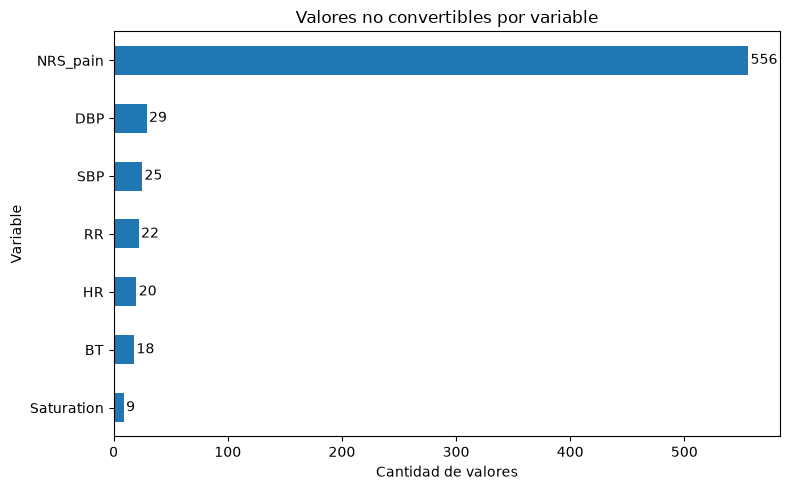

In [117]:
no_convertibles = {}

for c in cols_num:
    original = df[c].astype("string").str.strip()

    convertido = pd.to_numeric(original, errors="coerce")

    malos = original.notna() & original.ne("") & convertido.isna()
    no_convertibles[c] = malos.sum()

frecuencias = pd.Series(no_convertibles)
frecuencias = frecuencias[frecuencias > 0].sort_values()

ax = frecuencias.plot(kind="barh", figsize=(8, 5))

ax.set_title("Valores no convertibles por variable")
ax.set_xlabel("Cantidad de valores")
ax.set_ylabel("Variable")

for i, valor in enumerate(frecuencias):
    ax.text(valor + 2, i, str(valor), va="center")

plt.tight_layout()
plt.show()

-  En NRS_pain se encontró el marcador #BOÞ!, mientras que en las variables SBP, DBP, HR, RR, BT y Saturation se encontró el valor ??
- Podemos notar como la variable NRS_pain presenta una alta cantidad de estos valores (556 registros)
- Para tratarlos, se convertirán en NaN y posteriormente se evaluará cómo manejar los datos faltantes, sin eliminar automáticamente las filas que los contienen.

#### Analizamos valores faltantes nuevamente

In [118]:
# Convertir los valores no válidos a NaN
for c in cols_num:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    
#Diagnosticar los valores faltantes

faltantes = df.isna().sum()

diagnostico = pd.DataFrame({
    "Faltantes": faltantes,
    "Porcentaje (%)": (faltantes / len(df) * 100).round(2)
})

diagnostico = diagnostico.sort_values(
    "Porcentaje (%)", ascending=False
)

display(diagnostico)
    
    

,Faltantes,Porcentaje (%)
Saturation,697,55.01
NRS_pain,556,43.88
DBP,29,2.29
SBP,25,1.97
RR,22,1.74
HR,20,1.58
BT,18,1.42
Patients number per hour,0,0.00
Age,0,0.00
Sex,0,0.00


#### Revisamos distribucion de las columnas con valores faltantes

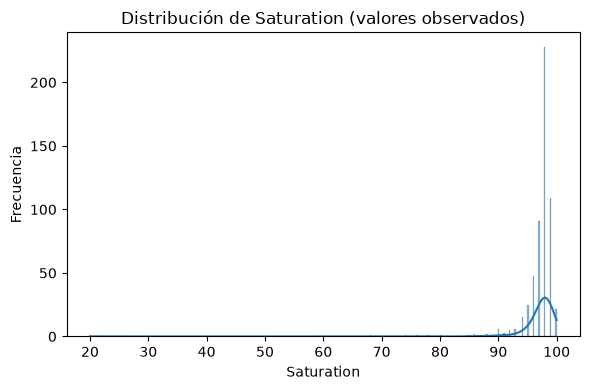

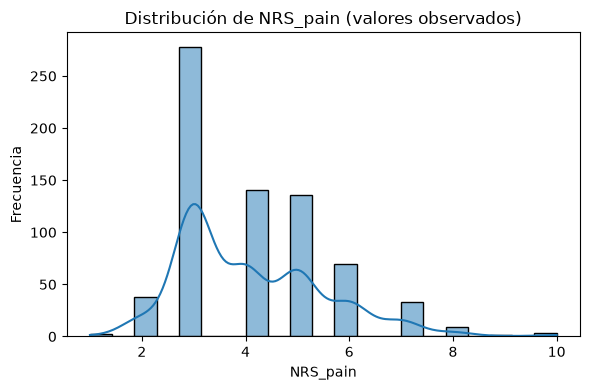

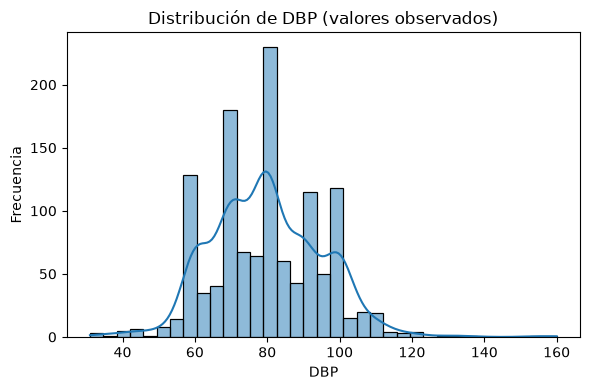

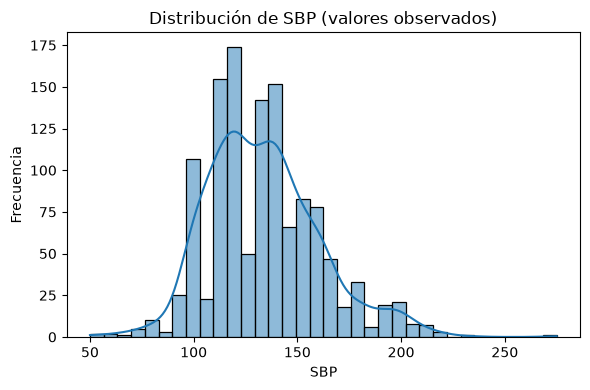

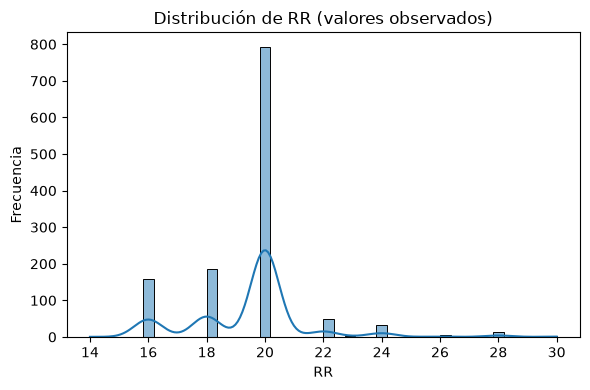

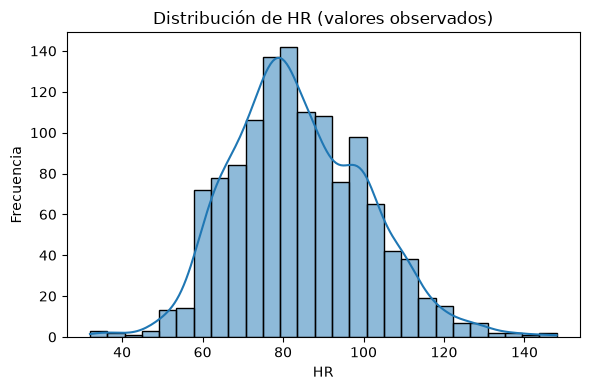

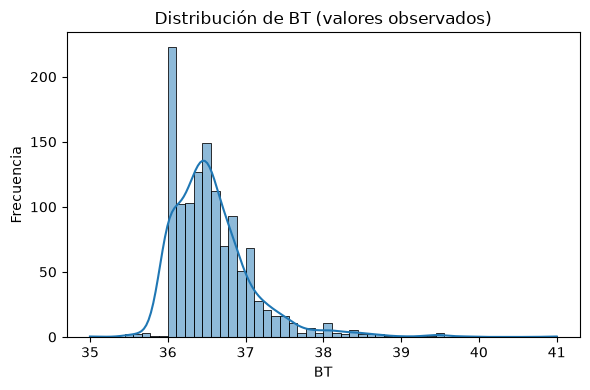

In [119]:

cols_faltantes = diagnostico[
    diagnostico["Faltantes"] > 0
].index.tolist()

cols_num_faltantes = [
    c for c in cols_faltantes if c in cols_num
]

for c in cols_num_faltantes:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[c].dropna(), kde=True)
    plt.title(f"Distribución de {c} (valores observados)")
    plt.xlabel(c)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

In [120]:

cols_faltantes = diagnostico[
    diagnostico["Faltantes"] > 0
].index.tolist()

# Resumen estadístico de las variables afectadas
resumen = df[cols_faltantes].describe().T

resumen["Faltantes"] = df[cols_faltantes].isna().sum()
resumen["% faltantes"] = (
    df[cols_faltantes].isna().mean() * 100
).round(2)

resumen["Asimetría"] = df[cols_faltantes].skew().round(2)

# Ordenar las columnas para facilitar la interpretación
resumen = resumen[
    [
        "count", "Faltantes", "% faltantes",
        "mean", "std", "50%", "min", "max", "Asimetría"
    ]
].rename(columns={
    "count": "Observados",
    "mean": "Media",
    "std": "Desv. estándar",
    "50%": "Mediana",
    "min": "Mínimo",
    "max": "Máximo"
}).round(2)

display(resumen)

,Observados,Faltantes,% faltantes,Media,Desv. estándar,Mediana,Mínimo,Máximo,Asimetría
Saturation,570.0,697,55.01,97.02,4.35,98.0,20.0,100.0,-11.22
NRS_pain,711.0,556,43.88,4.10,1.42,4.0,1.0,10.0,0.92
DBP,1238.0,29,2.29,79.78,15.15,80.0,31.0,160.0,0.35
SBP,1242.0,25,1.97,133.65,27.28,130.0,50.0,275.0,0.62
RR,1245.0,22,1.74,19.51,2.02,20.0,14.0,30.0,0.87
HR,1247.0,20,1.58,83.96,16.64,82.0,32.0,148.0,0.37
BT,1249.0,18,1.42,36.58,0.55,36.5,35.0,41.0,2.08


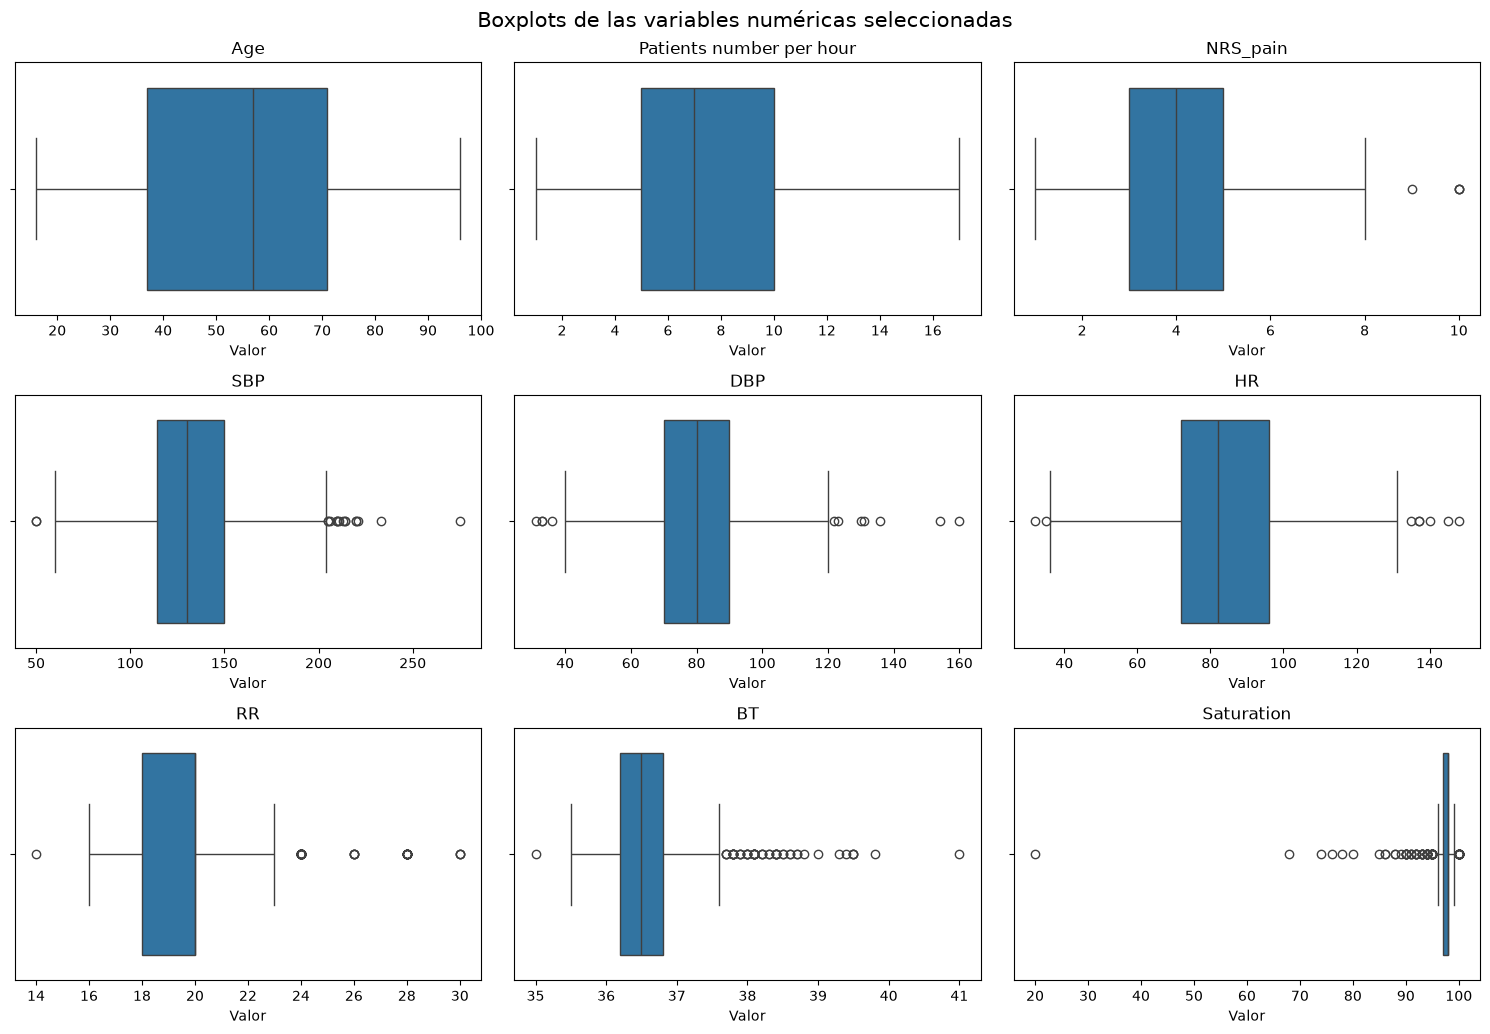

In [121]:

n_cols = 3
n_rows = math.ceil(len(cols_num) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, n_rows * 3.5)
)

axes = axes.flatten()

for i, c in enumerate(cols_num):
    sns.boxplot(
        x=df[c],
        ax=axes[i]
    )
    axes[i].set_title(c)
    axes[i].set_xlabel("Valor")

# Ocultar espacios sobrantes
for i in range(len(cols_num), len(axes)):
    axes[i].set_visible(False)

fig.suptitle(
    "Boxplots de las variables numéricas seleccionadas",
    fontsize=15
)

plt.tight_layout()
plt.show()

- Saturation: tiene 55,01 % de faltantes. La media es 97,02 y la mediana 98, pero la asimetría de −11,22 es extremadamente alta. El mínimo de 20 podría ser un valor real, un error de registro o un caso que requiere revisión

- NRS_pain: tiene 43,88 % de faltantes. La media (4,10) y la mediana (4) son muy similares, pero eso no resuelve el problema de que falta mucha información.

- DBP, SBP, RR y HR: tienen menos del 2,3 % de faltantes. La mediana es una opción razonable para una primera estrategia de imputación, porque es menos sensible a los valores extremos.

- BT: solo tiene 1,42 % de faltantes, pero presenta una asimetría de 2,08. La mediana también es una buena candidata.

#### Revisión de valores atípicos 


Antes de decidir imputar valores por el contexto decidimos quitar solo lo fisiológicamente imposible, y lo extremo pero real conservarlo

In [122]:
for c in ["Saturation", "BT", "RR", "SBP", "DBP", "HR"]:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1

    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr

    extremos = df.loc[
        df[c].notna() &
        ((df[c] < inferior) | (df[c] > superior)),
        c
    ].sort_values()

    print(f"\n--- {c} ---")
    print(f"Límite inferior: {inferior:.2f}")
    print(f"Límite superior: {superior:.2f}")
    print(f"Cantidad de posibles atípicos: {len(extremos)}")
    print(extremos.value_counts().sort_index().to_dict())


--- Saturation ---
Límite inferior: 95.50
Límite superior: 99.50
Cantidad de posibles atípicos: 94
{20.0: 1, 68.0: 1, 74.0: 1, 76.0: 1, 78.0: 1, 80.0: 1, 85.0: 1, 86.0: 2, 88.0: 2, 89.0: 1, 90.0: 6, 91.0: 3, 92.0: 5, 93.0: 6, 94.0: 15, 95.0: 25, 100.0: 22}

--- BT ---
Límite inferior: 35.30
Límite superior: 37.70
Cantidad de posibles atípicos: 50
{35.0: 1, 37.7: 3, 37.8: 7, 37.9: 3, 38.0: 4, 38.1: 7, 38.2: 3, 38.3: 2, 38.4: 5, 38.5: 2, 38.6: 2, 38.7: 2, 38.8: 1, 39.0: 1, 39.3: 1, 39.4: 1, 39.5: 3, 39.8: 1, 41.0: 1}

--- RR ---
Límite inferior: 15.00
Límite superior: 23.00
Cantidad de posibles atípicos: 55
{14.0: 1, 24.0: 34, 26.0: 4, 28.0: 13, 30.0: 3}

--- SBP ---
Límite inferior: 60.00
Límite superior: 204.00
Cantidad de posibles atípicos: 17
{50.0: 2, 205.0: 2, 206.0: 1, 210.0: 3, 211.0: 1, 213.0: 1, 214.0: 2, 220.0: 2, 221.0: 1, 233.0: 1, 275.0: 1}

--- DBP ---
Límite inferior: 40.00
Límite superior: 120.00
Cantidad de posibles atípicos: 11
{31.0: 1, 33.0: 2, 36.0: 1, 122.0: 1, 12

## Faltantes: qué significan y cómo los trato

Dos variables tienen muchos faltantes, pero por razones distintas.

- **NRS_pain (43,88 %, 556 faltantes):** no son datos perdidos. Crucé `Pain` con si `NRS_pain` estaba vacía: los 553 pacientes sin dolor (`Pain = 0`) tenían la escala vacía, y entre los que sí tenían dolor (`Pain = 1`) solo faltaban 3. Nadie le pregunta "¿cuánto dolor?" a quien no tiene dolor, así que el vacío significa **cero**. Por eso pongo `NRS_pain = 0` cuando `Pain = 0`, y no la mediana (4), que le diría al modelo que esos pacientes tienen dolor moderado. Quedan 3 faltantes reales.

- **Saturation (55,01 %, 697 faltantes):** tampoco faltan al azar. Crucé `Group` con si `Saturation` estaba vacía: el hospital 1 (local, tercer nivel) no la registra en ninguno de sus pacientes, y el hospital 2 (regional, cuarto nivel) la registra en todos. La media (97,02) y la mediana (98) son parecidas, pero la asimetría (−11,22) la causa un solo valor, el 20, que casi seguro es un error de registro (ver la sección de atípicos).

- **DBP, SBP, RR, HR y BT (menos del 2,3 % cada una):** son pocos faltantes y la mediana es una opción razonable, porque es menos sensible a los valores extremos. En BT la asimetría es 2,08 por la fiebre alta, que es información clínica real.

### Cuándo imputo

Los faltantes que quedan **no los relleno todavía**. Se imputan con la mediana dentro del `Pipeline`, después de separar 80/20, para que la mediana se calcule solo con entrenamiento y no se filtre información de prueba.

## Valores atípicos: qué se limpia y qué se conserva

Revisé los atípicos de cada variable con el método IQR. El problema es que, en datos clínicos, ese método marca como "atípico" muchos valores que son normales o que son justo los pacientes graves. Por eso no borré nada solo por salirse de los límites del IQR. Lo que me importa es si el valor es **posible fisiológicamente**.

| Variable | Rango observado | Atípicos IQR | Decisión | Por qué |
|---|---|---|---|---|
| Saturation | 20 a 100 | 94 | **Solo el 20 pasa a NaN**; el resto se conserva | El 20 % es casi seguro un error de registro. Los valores de 68 a 88 pueden ser hipoxemia real. El 100 es el máximo normal y el IQR lo marca solo porque el grueso está muy junto en 96-99 |
| BT | 35 a 41 | 50 | Se conserva | Va de hipotermia leve a fiebre muy alta, información útil para urgencia |
| RR | 14 a 30 | 55 | Se conserva | Es un rango razonable en urgencias; los 34 casos de 24 son taquipnea leve |
| SBP | 50 a 275 | 17 | Se conserva | Extremo, pero posible en shock o crisis hipertensiva |
| DBP | 31 a 160 | 11 | Se conserva | Igual que SBP; solo reviso que DBP no sea mayor que SBP |
| HR | 32 a 148 | 8 | Se conserva | Bradicardia y taquicardia reales |

### Por qué el 20 sí se limpia

El `StandardScaler` divide por la desviación estándar. En Saturation esa desviación es 4,35, pero casi todos los pacientes están entre 90 y 100, así que **un solo dato (el 20) la infla**. Esto tiene dos efectos:

- Las diferencias reales entre 94 y 100 quedan comprimidas, y la variable pierde sensibilidad justo donde importa.
- Ese registro queda con un valor estandarizado de aproximadamente -17, y en una regresión logística un punto así tiene mucha palanca sobre el coeficiente.

### Por qué los demás extremos se dejan

SBP de 275, BT de 41 o HR de 148 son raros, pero son posibles y corresponden a pacientes graves. El KTAS depende en buena parte de signos vitales alterados, así que quitarlos le quitaría al modelo la señal que más necesita para detectar urgencia.

### Decisión


1. Convertir `Saturation == 20` en `NaN` antes del pipeline, para que la mediana lo reemplace.
2. No tocar los demás extremos.
3. Revisé si había registros con `DBP >= SBP` (posibles errores de digitación) y no hay ninguno.

> **Limitación para documentar:** el hospital 1 no registra la saturación, así que esos pacientes quedan con la mediana, calculada con datos del hospital 2. El modelo no puede detectar hipoxemia en ellos. Lo reviso en el análisis de sesgo por hospital.

In [123]:
# revisar DBP ≥ SBP
mask_presion = df["DBP"] >= df["SBP"]
print("Registros con DBP >= SBP:", mask_presion.sum())
df.loc[mask_presion, ["SBP", "DBP"]]

Registros con DBP >= SBP: 0


,SBP,DBP


## Revisamos limpieza

In [124]:
# 1. Saturation = 20 a NaN
df.loc[df["Saturation"] == 20, "Saturation"] = np.nan

# 2. NRS_pain = 0 donde no hay dolor
df.loc[df["Pain"] == 0, "NRS_pain"] = 0

# 3. Arrival mode: 5 y 6 pasan a 7 (otro)
df["Arrival mode"] = df["Arrival mode"].replace({5: 7, 6: 7})

# Comprobación de faltantes
print(df[cols_num].isna().sum())

Age                           0
Patients number per hour      0
NRS_pain                      3
SBP                          25
DBP                          29
HR                           20
RR                           22
BT                           18
Saturation                  698
dtype: int64


## Agrupación de modos de llegada raros

Revisamos las variables categóricas (`Sex`, `Arrival mode`, `Injury`, `Mental`, `Pain`). No tienen faltantes ni valores mal escritos. El único problema está en `Arrival mode`, donde hay tres modos con muy pocos pacientes:

| Arrival mode | Pacientes antes | Pacientes después |
|---|---|---|
| 1 | 79 | 79 |
| 2 | 266 | 266 |
| 3 | 753 | 753 |
| 4 | 155 | 155 |
| 5 | 2 | (pasa a 7) |
| 6 | 10 | (pasa a 7) |
| 7 | 2 | 14 |

### Por qué los junto

Con el one-hot, cada categoría se vuelve una columna. Los modos 5 y 7 tienen solo 2 pacientes cada uno, así que serían columnas casi vacías que aportan ruido, y con el 80/20 podrían quedar en una sola partición. Ademas se agruparon los modos 5, 6 y 7 en una sola categoría "otro" (7) ya que 5, 6 y 7 son “otro”. Eso respalda agruparlos: los tres significan lo mismo

### Qué se dejo como está

`Mental` tiene niveles pequeños (39, 28 y 13 pacientes), pero **no se juntaron**. Son niveles de conciencia y los pacientes con alteración mental suelen ser los graves, así que juntarlos borraría justo la señal que importa.

Hago esta agrupación antes de separar 80/20. Es una regla fija que no calcula nada con los datos, así que no hay fuga de información.

Confirmamos que los 553 pacientes sin dolor (Pain = 0) tienen NRS_pain vacío todos, y entre los que sí tienen dolor (Pain = 1) solo faltan 3 de 714. Así que esos faltantes no son datos perdidos

### Revisamos variables categoricas

"Sex", "Arrival mode", "Injury", "Mental", "Pain"

In [125]:
for col in cols_cat:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- Sex ---
Sex
2    661
1    606
Name: count, dtype: int64

--- Arrival mode ---
Arrival mode
3    753
2    266
4    155
1     79
7     14
Name: count, dtype: int64

--- Injury ---
Injury
1    1023
2     244
Name: count, dtype: int64

--- Mental ---
Mental
1    1187
2      39
3      28
4      13
Name: count, dtype: int64

--- Pain ---
Pain
1    714
0    553
Name: count, dtype: int64



Ninguna variable tiene NaN (dropna=False no mostró ninguno) ni valores raros escritos como texto, así que la limpieza de categóricas se reduce a un solo punto

### Revision final EDA

In [126]:

cols_num = ["Age", "Patients number per hour", "NRS_pain", "SBP", "DBP", "HR", "RR", "BT", "Saturation"]

print(df[cols_num].isna().sum())
print()
print(df[cols_num].describe().T[["min", "max"]])

Age                           0
Patients number per hour      0
NRS_pain                      3
SBP                          25
DBP                          29
HR                           20
RR                           22
BT                           18
Saturation                  698
dtype: int64

                           min    max
Age                       16.0   96.0
Patients number per hour   1.0   17.0
NRS_pain                   0.0   10.0
SBP                       50.0  275.0
DBP                       31.0  160.0
HR                        32.0  148.0
RR                        14.0   30.0
BT                        35.0   41.0
Saturation                68.0  100.0


## Verificación de la limpieza de variables numéricas

Después de aplicar los dos arreglos manuales (Saturation = 20 a `NaN` y `NRS_pain` = 0 cuando no hay dolor), revisé que los cambios quedaran bien.

| Variable | Faltantes | Mínimo | Máximo |
|---|---|---|---|
| Age | 0 | 16 | 96 |
| Patients number per hour | 0 | 1 | 17 |
| NRS_pain | 3 | 0 | 10 |
| SBP | 25 | 50 | 275 |
| DBP | 29 | 31 | 160 |
| HR | 20 | 32 | 148 |
| RR | 22 | 14 | 30 |
| BT | 18 | 35 | 41 |
| Saturation | 698 | 68 | 100 |

Lo que confirma la tabla:

- **Saturation:** el mínimo pasó de 20 a 68 y los faltantes subieron de 697 a 698, así que el cambio se aplicó a un solo registro.
- **NRS_pain:** el mínimo ahora es 0 y los faltantes bajaron de 556 a 3. Los 553 pacientes sin dolor (`Pain = 0`) tenían la escala vacía, y eso significaba "cero dolor", no un dato perdido.
- **Resto de variables:** los mínimos y máximos no cambiaron, porque decidí conservar los extremos que son clínicamente posibles.

### Qué falta por tratar: los `NaN`

Los faltantes que quedan **no los imputo todavía** a propósito. Se van a rellenar con la mediana dentro del `Pipeline`, después de separar 80/20. Así la mediana se calcula solo con los datos de entrenamiento y se aplica igual a los de prueba, y no se filtra información de prueba al entrenamiento.

Los faltantes que quedan son:

- **Saturation (698, 55 %):** es la más imputada del dataset. Lo dejo anotado como limitación en `DATASETS.md`.
- **NRS_pain (3):** pacientes con dolor pero sin número registrado.
- **SBP, DBP, HR, RR y BT (menos del 2,3 % cada una):** son pocos y la mediana es una opción razonable.

---
## Preparación de los datos

**Separación 80/20.**

El 80 % se utiliza para entrenar y el 20 % se reserva para la evaluación final. `stratify=y` conserva la proporción de clases y `random_state=42` permite reproducir la separación


In [127]:
from sklearn.model_selection import train_test_split

X = df  # las 14 variables de entrada

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# hospital de los pacientes de prueba, para el análisis de sesgo
grupo_test = grupo.loc[X_test.index]

# comprobaciones
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("\nProporción de urgentes:")
print("Total:        ", round(y.mean(), 3))
print("Entrenamiento:", round(y_train.mean(), 3))
print("Prueba:       ", round(y_test.mean(), 3))

Entrenamiento: (1013, 14) | Prueba: (254, 14)

Proporción de urgentes:
Total:         0.579
Entrenamiento: 0.578
Prueba:        0.579


### Revisión de la partición de los datos

Los tamaños de los conjuntos son los esperados (1013 registros para entrenamiento y 254 para prueba). Además, la proporción de pacientes urgentes es prácticamente idéntica en ambos conjuntos (57,8 % y 57,9 %, respectivamente), lo que indica que la estratificación mediante `stratify` funcionó correctamente.

La distribución de las clases es relativamente equilibrada, con aproximadamente un 58 % de pacientes urgentes y un 42 % de no urgentes. Por tanto, inicialmente no parece necesario aplicar técnicas especiales para el desbalance de clases, aunque su impacto se evaluará mediante las métricas de desempeño del modelo.

---

## Construcción del pipeline

Un `Pipeline` permite encadenar los pasos del preprocesamiento y el modelo en un solo objeto. Al ejecutar `fit` con los datos de entrenamiento, cada paso aprende únicamente de ese conjunto: la mediana se calcula con los datos de entrenamiento y el escalador aprende su media y desviación estándar. Después, esos mismos parámetros se aplican al conjunto de prueba, evitando la fuga de información (*data leakage*).

Como las variables numéricas y categóricas requieren tratamientos diferentes, se utiliza un `ColumnTransformer`, que permite procesar cada grupo por separado:

- **Variables numéricas (`cols_num`):** se utiliza `SimpleImputer` con la mediana para reemplazar los valores `NaN` y, posteriormente, `StandardScaler` para estandarizar las variables. Esto facilita que la regresión logística trabaje con variables en escalas comparables, sin que las magnitudes numéricas más grandes dominen por su escala.

- **Variables categóricas (`cols_cat`):** se utiliza `OneHotEncoder` para convertir cada categoría en una columna binaria. Aunque algunas variables, como `Arrival mode` y `Mental`, estén representadas mediante números, esos valores identifican categorías y no necesariamente cantidades ordenadas. La codificación evita que el modelo interprete sus códigos como magnitudes numéricas.

- **`handle_unknown="ignore"`:** permite procesar categorías que aparezcan en prueba, pero que no se hayan observado durante el entrenamiento, sin generar un error.

De esta manera, el pipeline integra el preprocesamiento y la regresión logística, garantizando que los parámetros de transformación se aprendan únicamente con los datos de entrenamiento.

In [128]:
#pipeline

pre_num = Pipeline([
    ("mediana", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
])

pre_cat = OneHotEncoder(handle_unknown="ignore")

preprocesamiento = ColumnTransformer([
    ("num", pre_num, cols_num),
    ("cat", pre_cat, cols_cat),
])

modelo = Pipeline([
    ("prep", preprocesamiento),
    ("clf", LogisticRegression(max_iter=1000)),
])

### Validación cruzada de 5 particiones (sobre entrenamiento)

In [129]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_cv = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="roc_auc")

print("AUC por partición:", auc_cv.round(3))
print("AUC medio:", auc_cv.mean().round(3), "+/-", auc_cv.std().round(3))

c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


AUC por partición: [0.816 0.811 0.809 0.787 0.82 ]
AUC medio: 0.809 +/- 0.011


c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


---
# Elección del modelo supervisado

**Todavía no hay modelo elegido.** Aquí se comparan, en igualdad de condiciones, todos los candidatos: regresión logística, árbol de decisión, KNN, SVM (lineal y rbf), Gradient Boosting, XGBoost, LightGBM, CatBoost y dos redes MLP. La regresión lineal entra solo como referencia. **El que gane se usa para todo lo que sigue** (evaluación en prueba, umbrales, sesgo y guardado).

**Reglas del experimento, fijadas antes de ver resultados:**

1. Todos los modelos reciben **el mismo preprocesamiento** (mediana → estandarización → one-hot) dentro de un `Pipeline`, así que ninguno ve información de validación al calcular medianas o escalas.
2. Todos usan **las mismas 5 particiones** de validación cruzada, calculadas sobre el entrenamiento.
3. **Se elige por AUC en validación cruzada**, no por el rendimiento en entrenamiento (premia memorizar). **La prueba no se toca en esta sección:** se usa una sola vez, después, con el modelo elegido. Así sigue siendo una medida independiente.
4. Si varios modelos quedan **dentro de una desviación estándar** del mejor, se consideran empatados y gana el más explicable, siguiendo este orden: regresión logística, árbol, SVM lineal, KNN, boosting, SVM rbf, redes.
5. Los umbrales y el sesgo de las secciones siguientes se recalculan solos con el modelo elegido. Los textos escritos a mano y `entrenar.py` están redactados para la regresión logística: si gana otro modelo, hay que revisarlos.

In [130]:
# Solo la primera vez. Si instala algo nuevo, reinicie el kernel y ejecute el cuaderno desde el principio.
# %pip install -q xgboost lightgbm catboost

In [131]:
import time, warnings
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate
pre = preprocesamiento

# (KNN, boosting y redes trabajan más cómodos así). clone() crea una copia SIN entrenar

try:
    pre_d = clone(pre).set_params(cat__sparse_output=False)
except ValueError:                      # versiones antiguas de scikit-learn
    pre_d = clone(pre).set_params(cat__sparse=False)

candidatos = {
    "Regresión logística": LogisticRegression(max_iter=1000),
    "Árbol de decisión":   DecisionTreeClassifier(max_depth=3, random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=15),
    "SVM lineal":          SVC(kernel="linear", probability=True, random_state=42),
    "SVM rbf":             SVC(kernel="rbf", C=1.0, probability=True, random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42),
    "MLP sin regularizar": MLPClassifier(hidden_layer_sizes=(16, 8), alpha=1e-4, max_iter=3000, random_state=42),
    "MLP regularizado":    MLPClassifier(hidden_layer_sizes=(16,), alpha=1.0, max_iter=3000, random_state=42),
}

# Las tres librerías de boosting modernas son opcionales: si no están, se omiten.
try:
    from xgboost import XGBClassifier
    candidatos["XGBoost"] = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
except Exception as e_:
    print("XGBoost no disponible, se omite:", type(e_).__name__)
try:
    from lightgbm import LGBMClassifier
    candidatos["LightGBM"] = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, random_state=42, verbose=-1)
except Exception as e_:
    print("LightGBM no disponible, se omite:", type(e_).__name__)
try:
    from catboost import CatBoostClassifier
    candidatos["CatBoost"] = CatBoostClassifier(iterations=300, depth=4, learning_rate=0.05, verbose=0, random_seed=42)
except Exception as e_:
    print("CatBoost no disponible, se omite:", type(e_).__name__)

# Orden de preferencia por explicabilidad, usado SOLO para desempatar (regla 4)
ORDEN_EXPLICABILIDAD = ["Regresión logística", "Árbol de decisión", "SVM lineal", "KNN",
                        "Gradient Boosting", "XGBoost", "LightGBM", "CatBoost",
                        "SVM rbf", "MLP regularizado", "MLP sin regularizar"]

print(len(candidatos), "modelos a comparar:", list(candidatos))

11 modelos a comparar: ['Regresión logística', 'Árbol de decisión', 'KNN', 'SVM lineal', 'SVM rbf', 'Gradient Boosting', 'MLP sin regularizar', 'MLP regularizado', 'XGBoost', 'LightGBM', 'CatBoost']


In [132]:
def evaluar_candidato(nombre, clf):
    pipe = Pipeline([("pre", clone(pre_d)), ("clf", clone(clf))])
    t0 = time.time()
    r = cross_validate(pipe, X_train, y_train, cv=cv, return_train_score=True,
                       scoring={"auc": "roc_auc", "brier": "neg_brier_score"})
    return {"modelo": nombre,
            "AUC_cv": r["test_auc"].mean(),
            "desviacion": r["test_auc"].std(),
            "AUC_entrenamiento": r["train_auc"].mean(),
            "brecha": r["train_auc"].mean() - r["test_auc"].mean(),
            "Brier_cv": -r["test_brier"].mean(),
            "segundos": round(time.time() - t0, 1)}

filas = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for nombre, clf in candidatos.items():
        filas.append(evaluar_candidato(nombre, clf))
        print(f"{nombre:22s} AUC_cv {filas[-1]['AUC_cv']:.3f} ± {filas[-1]['desviacion']:.3f}")

tabla_sup = pd.DataFrame(filas).set_index("modelo").sort_values("AUC_cv", ascending=False)
tabla_sup.round(3)

Regresión logística    AUC_cv 0.809 ± 0.011
Árbol de decisión      AUC_cv 0.729 ± 0.025
KNN                    AUC_cv 0.753 ± 0.012
SVM lineal             AUC_cv 0.808 ± 0.015
SVM rbf                AUC_cv 0.800 ± 0.009
Gradient Boosting      AUC_cv 0.821 ± 0.012
MLP sin regularizar    AUC_cv 0.804 ± 0.019
MLP regularizado       AUC_cv 0.797 ± 0.013
XGBoost                AUC_cv 0.833 ± 0.007
LightGBM               AUC_cv 0.810 ± 0.015
CatBoost               AUC_cv 0.829 ± 0.012


,AUC_cv,desviacion,AUC_entrenamiento,brecha,Brier_cv,segundos
modelo,,,,,,
XGBoost,0.833,0.007,0.928,0.095,0.165,4.4
CatBoost,0.829,0.012,0.971,0.142,0.166,6.8
Gradient Boosting,0.821,0.012,0.948,0.127,0.171,3.8
LightGBM,0.810,0.015,0.995,0.185,0.178,1.5
Regresión logística,0.809,0.011,0.827,0.018,0.175,0.6
SVM lineal,0.808,0.015,0.820,0.012,0.177,2.5
MLP sin regularizar,0.804,0.019,0.936,0.132,0.186,11.9
SVM rbf,0.800,0.009,0.887,0.088,0.180,3.8
MLP regularizado,0.797,0.013,0.835,0.038,0.182,3.8


----

### Comparacion final - Graficas

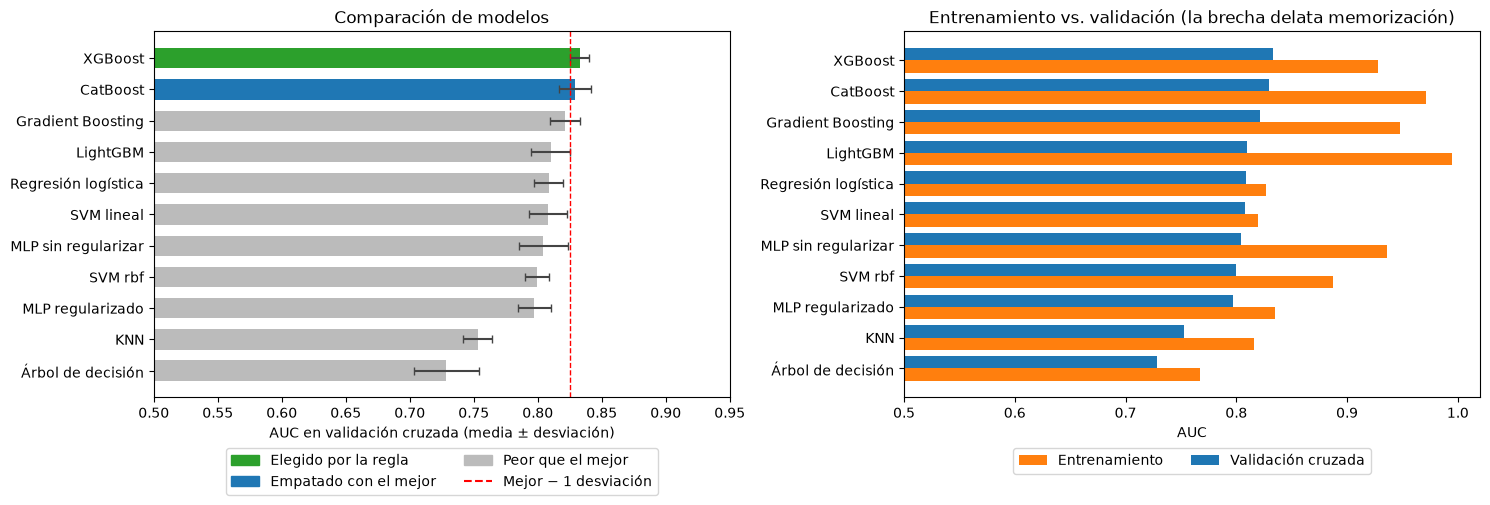

Mejor AUC en validación cruzada: XGBoost (0.833 ± 0.007)
Empatados (AUC_cv >= 0.825): XGBoost, CatBoost
Elegido según la regla de explicabilidad: XGBoost


In [133]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Regla de decisión: empate = dentro de una desviación del mejor
mejor_sup = tabla_sup["AUC_cv"].idxmax()
corte = tabla_sup.loc[mejor_sup, "AUC_cv"] - tabla_sup.loc[mejor_sup, "desviacion"]
empatados = tabla_sup.index[tabla_sup["AUC_cv"] >= corte].tolist()
elegido_sup = next(m for m in ORDEN_EXPLICABILIDAD if m in empatados)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))

# 1) Comparación por validación cruzada (lo que decide)
g = tabla_sup[["AUC_cv", "desviacion"]].sort_values("AUC_cv")

def _color(m_):
    return "#2ca02c" if m_ == elegido_sup else "#1f77b4" if m_ in empatados else "#bbbbbb"

ax[0].barh(g.index, g["AUC_cv"], xerr=g["desviacion"], color=[_color(m_) for m_ in g.index],
           height=0.65, error_kw={"ecolor": "#444444", "capsize": 3})
ax[0].axvline(corte, color="red", ls="--", lw=1)
ax[0].set_xlim(0.5, 0.95)
ax[0].set_xlabel("AUC en validación cruzada (media ± desviación)")
ax[0].set_title("Comparación de modelos")
ax[0].legend(handles=[Patch(color="#2ca02c", label="Elegido por la regla"),
                      Patch(color="#1f77b4", label="Empatado con el mejor"),
                      Patch(color="#bbbbbb", label="Peor que el mejor"),
                      Line2D([0], [0], color="red", ls="--", label="Mejor − 1 desviación")],
             loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

# 2) Entrenamiento vs validación: quien memoriza rinde mucho mejor en entrenamiento
t_ = tabla_sup.sort_values("AUC_cv")
pos = np.arange(len(t_))
ax[1].barh(pos - 0.2, t_["AUC_entrenamiento"], height=0.4, color="#ff7f0e", label="Entrenamiento")
ax[1].barh(pos + 0.2, t_["AUC_cv"], height=0.4, color="#1f77b4", label="Validación cruzada")
ax[1].set_yticks(pos)
ax[1].set_yticklabels(t_.index)
ax[1].set_xlim(0.5, 1.02)
ax[1].set_xlabel("AUC")
ax[1].set_title("Entrenamiento vs. validación (la brecha delata memorización)")
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

plt.tight_layout()
plt.show()

print(f"Mejor AUC en validación cruzada: {mejor_sup} ({tabla_sup.loc[mejor_sup, 'AUC_cv']:.3f} ± {tabla_sup.loc[mejor_sup, 'desviacion']:.3f})")
print(f"Empatados (AUC_cv >= {corte:.3f}): {', '.join(empatados)}")
print(f"Elegido según la regla de explicabilidad: {elegido_sup}")

## Resultados de la comparación de modelos

Todos los candidatos se evaluaron con el mismo preprocesamiento y las mismas 5 particiones de validación cruzada sobre el conjunto de entrenamiento. La prueba no se usó en esta sección.

| Modelo | AUC en validación cruzada | AUC en entrenamiento | Brecha |
|---|---|---|---|
| XGBoost | 0,833 ± 0,007 | 0,928 | 0,095 |
| CatBoost | 0,829 ± 0,012 | 0,971 | 0,142 |
| Gradient Boosting | 0,821 ± 0,012 | 0,948 | 0,127 |
| LightGBM | 0,810 ± 0,015 | 0,995 | 0,185 |
| Regresión logística | 0,809 ± 0,011 | 0,827 | 0,018 |
| SVM lineal | 0,808 ± 0,015 | 0,820 | 0,012 |
| MLP sin regularizar | 0,804 ± 0,019 | 0,936 | 0,132 |
| SVM rbf | 0,800 ± 0,009 | 0,887 | 0,088 |
| MLP regularizado | 0,797 ± 0,013 | 0,835 | 0,038 |
| KNN | 0,753 ± 0,012 | 0,816 | 0,063 |
| Árbol de decisión | 0,729 ± 0,025 | 0,767 | 0,038 |

### Lectura de los resultados

- **Los modelos de boosting lideran.** XGBoost obtiene el mejor AUC (0,833) y también la menor desviación entre particiones (0,007), así que es el más estable.
- **Los modelos lineales quedan cerca.** La regresión logística (0,809) y la SVM lineal (0,808) están a unos 2,4 puntos de AUC del mejor, y con una brecha mínima entre entrenamiento y validación (0,018 y 0,012), es decir, casi no memorizan.
- **KNN y el árbol de decisión rinden peor** (0,753 y 0,729). El árbol, limitado a profundidad 3 para que sea interpretable, no alcanza a capturar la relación entre las variables.
- **La brecha delata la memorización.** LightGBM llega a 0,995 en entrenamiento pero solo 0,810 en validación (brecha de 0,185), y CatBoost a 0,971 contra 0,829. Un AUC tan alto en entrenamiento no se traduce en mejor rendimiento con pacientes nuevos, por eso la elección se hace solo con validación cruzada.

### Aplicación de la regla de decisión

- Mejor AUC en validación cruzada: **XGBoost** (0,833 ± 0,007).
- Corte de empate (mejor − 1 desviación): 0,833 − 0,007 = **0,826**.
- Modelos que quedan dentro del empate: XGBoost (0,833) y CatBoost (0,829).
- Entre los empatados, el orden de explicabilidad favorece a XGBoost.

**Modelo elegido: XGBoost.** La regresión logística (0,809) queda fuera del empate, por debajo del corte.

### Consideraciones para lo que sigue

- XGBoost tiene una brecha de 0,095 entre entrenamiento y validación, mayor que la de la regresión logística (0,018). Es moderada, y su AUC en validación sigue siendo el más alto.
- Los umbrales de decisión y de caso crítico, el análisis de sesgo y el guardado se recalculan con el modelo elegido, y los textos escritos para la regresión logística hay que revisarlos.

---

### Decisión

Con la comparación hecha, queda escrito qué modelo se usa de aquí en adelante.

In [134]:
print(f"Modelo elegido: {elegido_sup}")
if elegido_sup == "Regresión logística":
    print("Se usa para la evaluación en prueba, los umbrales (0.4 y 0.9), el sesgo y el guardado.")
else:
    print(f"El resto del cuaderno se calculará con {elegido_sup}.")
    print("Recordatorio: confirmar que los textos, los umbrales 0.4 y 0.9 y entrenar.py correspondan a este modelo.")

Modelo elegido: XGBoost
El resto del cuaderno se calculará con XGBoost.
Recordatorio: confirmar que los textos, los umbrales 0.4 y 0.9 y entrenar.py correspondan a este modelo.


### Modelo final

Se construye con el algoritmo elegido arriba, con el mismo preprocesamiento y las mismas particiones, y se entrena con el 80 %. **A partir de aquí todo (prueba, umbrales, sesgo y guardado) usa este modelo.**

In [135]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

if "pre" not in globals():
    pre = preprocesamiento

# Modelos que en la comparación usaron el preprocesamiento denso (pre_d)
USA_DENSO = {"KNN", "Gradient Boosting", "XGBoost", "LightGBM", "CatBoost",
             "MLP sin regularizar", "MLP regularizado"}
pre_final = pre_d if elegido_sup in USA_DENSO else pre

modelo = Pipeline([("pre", clone(pre_final)), ("clf", clone(candidatos[elegido_sup]))])

auc_cv = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="roc_auc")
print(auc_cv.round(3), auc_cv.mean().round(3))

modelo.fit(X_train, y_train)

[0.819 0.84  0.838 0.83  0.836] 0.833


Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('mediana',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalador',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Patients number per hour',
                                                   'NRS_pain', 'SBP', 'DBP',
                                                   'HR', 'RR', 'BT',
                                                   'Saturation']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Sex', 'Arrival mode',
                                                   'Injury', 'Mental',
                                                   'Pain...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [136]:

from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, f1_score

proba = modelo.predict_proba(X_test)[:, 1]
print("AUC prueba:", round(roc_auc_score(y_test, proba), 3))

def metricas(umbral):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"umbral": umbral,
            "sens": round(tp / (tp + fn), 3), "espec": round(tn / (tn + fp), 3),
            "prec": round(precision_score(y_test, pred), 3), "f1": round(f1_score(y_test, pred), 3),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

pd.DataFrame([metricas(u) for u in [0.5, 0.4, 0.3]])

AUC prueba: 0.765


,umbral,sens,espec,prec,f1,TN,FP,FN,TP
0,0.5,0.810,0.579,0.726,0.765,62,45,28,119
1,0.4,0.884,0.514,0.714,0.790,55,52,17,130
2,0.3,0.918,0.411,0.682,0.783,44,63,12,135


---

## Evaluación en el conjunto de prueba

El modelo final se evalúa con el 20 % de los datos reservado, que no se usó en el entrenamiento ni en la elección del modelo.

**Métricas**

- **AUC:** capacidad del modelo para distinguir entre pacientes urgentes y no urgentes, sin depender de un umbral.
- **Sensibilidad:** proporción de pacientes urgentes que el modelo detecta.
- **Especificidad:** proporción de pacientes no urgentes identificados correctamente.
- **Precisión:** proporción de predicciones "urgente" que son correctas.
- **F1:** equilibrio entre precisión y sensibilidad.
- **Matriz de confusión:** resume aciertos y errores, y muestra los falsos negativos (urgentes que el modelo no detectó).

**Umbral de decisión**

El umbral es la probabilidad a partir de la cual se clasifica un paciente como urgente. En triage importa más no dejar pasar a un paciente urgente que generar una falsa alarma, así que se compara el umbral habitual (0.5) con valores más bajos (0.4 y 0.3). Bajar el umbral aumenta la detección de urgentes, pero también las falsas alarmas.

In [137]:
from sklearn.metrics import (roc_auc_score, confusion_matrix,
                             precision_score, f1_score)

from sklearn.model_selection import cross_val_predict

proba_cv = cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

for u in [0.5, 0.4, 0.3]:
    pred = (proba_cv >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    print(f"umbral {u}: sensibilidad {tp/(tp+fn):.3f} | especificidad {tn/(tn+fp):.3f} | urgentes perdidos {fn}")

umbral 0.5: sensibilidad 0.829 | especificidad 0.663 | urgentes perdidos 100
umbral 0.4: sensibilidad 0.881 | especificidad 0.571 | urgentes perdidos 70
umbral 0.3: sensibilidad 0.930 | especificidad 0.457 | urgentes perdidos 41


### Elección del umbral de decisión

Para no usar la prueba en esta decisión, los umbrales se compararon con predicciones de validación cruzada sobre el entrenamiento (1013 pacientes, 586 urgentes).

| Umbral | Sensibilidad | Especificidad | Urgentes perdidos |
|---|---|---|---|
| 0.5 | 0,829 | 0,663 | 100 |
| 0.4 | 0,881 | 0,571 | 70 |
| 0.3 | 0,930 | 0,457 | 41 |

Bajar el umbral detecta más pacientes urgentes, pero cada paso cuesta más falsas alarmas. De 0.5 a 0.4 se recuperan 30 urgentes y se suman unas 39 falsas alarmas; de 0.4 a 0.3 se recuperan 29 y se suman unas 49. Con 0.3 casi la mitad de los pacientes no urgentes quedaría marcada como urgente.

Se escoge **0.4** como umbral de decisión: detecta casi 9 de cada 10 urgentes y mantiene una especificidad de 0,571. Aun así, se pierden 70 urgentes (12 %), por lo que el modelo apoya la decisión del clínico y no la reemplaza.

In [138]:
from sklearn.model_selection import cross_val_score

auc_cv = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="roc_auc")
print(auc_cv.round(3), auc_cv.mean().round(3))

[0.819 0.84  0.838 0.83  0.836] 0.833


In [139]:
import pandas as pd
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, f1_score

proba = modelo.predict_proba(X_test)[:, 1]
print("AUC prueba:", round(roc_auc_score(y_test, proba), 3))

def metricas(umbral):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"umbral": umbral,
            "sens": round(tp / (tp + fn), 3), "espec": round(tn / (tn + fp), 3),
            "prec": round(precision_score(y_test, pred), 3), "f1": round(f1_score(y_test, pred), 3),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

pd.DataFrame([metricas(u) for u in [0.5, 0.4, 0.3]])

AUC prueba: 0.765


,umbral,sens,espec,prec,f1,TN,FP,FN,TP
0,0.5,0.810,0.579,0.726,0.765,62,45,28,119
1,0.4,0.884,0.514,0.714,0.790,55,52,17,130
2,0.3,0.918,0.411,0.682,0.783,44,63,12,135


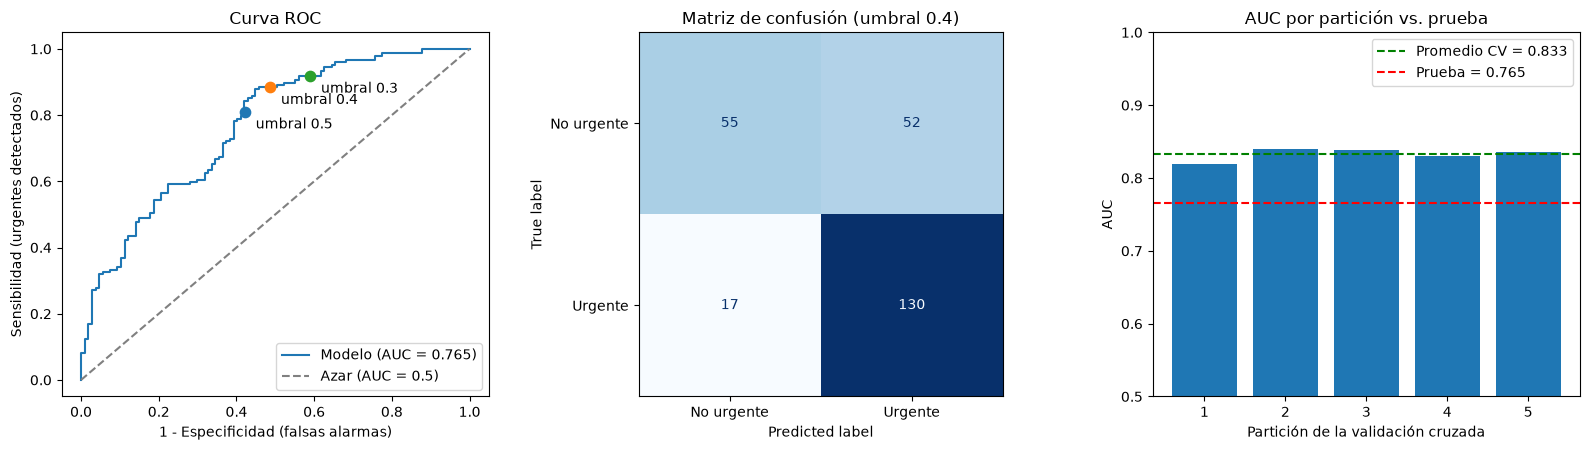

In [140]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

UMBRAL = 0.4

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

# 1) Curva ROC con los umbrales marcados
fpr, tpr, _ = roc_curve(y_test, proba)
ax[0].plot(fpr, tpr, label=f"Modelo (AUC = {roc_auc_score(y_test, proba):.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0.5)")
for u in [0.5, 0.4, 0.3]:
    mu = metricas(u)
    ax[0].scatter(1 - mu["espec"], mu["sens"], s=55, zorder=3)
    ax[0].annotate(f"umbral {u}", (1 - mu["espec"], mu["sens"]), textcoords="offset points", xytext=(8, -12))
ax[0].set_xlabel("1 - Especificidad (falsas alarmas)")
ax[0].set_ylabel("Sensibilidad (urgentes detectados)")
ax[0].set_title("Curva ROC")
ax[0].legend(loc="lower right")

# 2) Matriz de confusión con el umbral elegido
ConfusionMatrixDisplay.from_predictions(
    y_test, (proba >= UMBRAL).astype(int),
    display_labels=["No urgente", "Urgente"], cmap="Blues", ax=ax[1], colorbar=False)
ax[1].set_title(f"Matriz de confusión (umbral {UMBRAL})")

# 3) Estabilidad: AUC por partición frente al AUC de prueba
ax[2].bar(range(1, 6), auc_cv, color="#1f77b4")
ax[2].axhline(auc_cv.mean(), color="green", ls="--", label=f"Promedio CV = {auc_cv.mean():.3f}")
ax[2].axhline(roc_auc_score(y_test, proba), color="red", ls="--", label=f"Prueba = {roc_auc_score(y_test, proba):.3f}")
ax[2].set_ylim(0.5, 1)
ax[2].set_xlabel("Partición de la validación cruzada")
ax[2].set_ylabel("AUC")
ax[2].set_title("AUC por partición vs. prueba")
ax[2].legend()

plt.tight_layout()
plt.show()

### Resultados gráficos en el conjunto de prueba

- **Curva ROC:** el modelo se separa claramente del azar (AUC = 0,765). Los tres umbrales evaluados quedan en la zona de alta sensibilidad (0,81 a 0,92), a costa de una proporción alta de falsas alarmas.
- **Matriz de confusión (umbral 0,4):** de los 147 pacientes urgentes se detectan 130 y se pierden 17. De los 107 no urgentes, 55 se clasifican bien y 52 se marcan como urgentes.
- **Estabilidad:** el AUC de las cinco particiones de validación cruzada está entre 0,819 y 0,840, mientras que en prueba es 0,765, por debajo de todas. La diferencia se discute en la sección anterior.

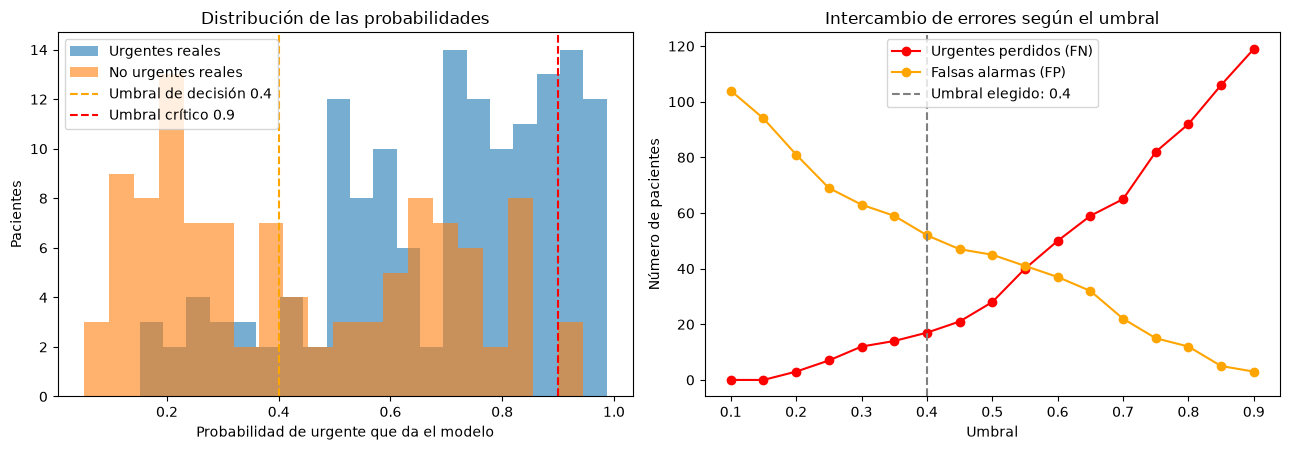

umbral 0.7: 104 de 254 pacientes de prueba por encima
umbral 0.8: 67 de 254 pacientes de prueba por encima
umbral 0.9: 31 de 254 pacientes de prueba por encima


In [141]:
yt = y_test.values
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

# 1) Cómo reparte el modelo sus probabilidades
ax[0].hist(proba[yt == 1], bins=20, alpha=0.6, label="Urgentes reales")
ax[0].hist(proba[yt == 0], bins=20, alpha=0.6, label="No urgentes reales")
ax[0].axvline(0.4, color="orange", ls="--", label="Umbral de decisión 0.4")
ax[0].axvline(0.9, color="red", ls="--", label="Umbral crítico 0.9")
ax[0].set_xlabel("Probabilidad de urgente que da el modelo")
ax[0].set_ylabel("Pacientes")
ax[0].set_title("Distribución de las probabilidades")
ax[0].legend()

# 2) Intercambio entre urgentes perdidos y falsas alarmas según el umbral
us = np.arange(0.1, 0.91, 0.05)
fn_ = [int(((proba < u) & (yt == 1)).sum()) for u in us]
fp_ = [int(((proba >= u) & (yt == 0)).sum()) for u in us]
ax[1].plot(us, fn_, "o-", color="red", label="Urgentes perdidos (FN)")
ax[1].plot(us, fp_, "o-", color="orange", label="Falsas alarmas (FP)")
ax[1].axvline(0.4, color="gray", ls="--", label="Umbral elegido: 0.4")
ax[1].set_xlabel("Umbral")
ax[1].set_ylabel("Número de pacientes")
ax[1].set_title("Intercambio de errores según el umbral")
ax[1].legend()

plt.tight_layout()
plt.show()

for u in [0.7, 0.8, 0.9]:
    print(f"umbral {u}: {int((proba >= u).sum())} de {len(proba)} pacientes de prueba por encima")

### Distribución de las probabilidades y umbral crítico

- Los pacientes urgentes reciben en su mayoría probabilidades entre 0,5 y 1,0, y los no urgentes se concentran por debajo de 0,4, aunque hay un traslape amplio en el rango de 0,4 a 0,85. Esto es coherente con un AUC de 0,765.
- Los no urgentes forman una segunda acumulación entre 0,7 y 0,85: son pacientes a los que el modelo asigna una probabilidad alta pese a no ser urgentes.
- Las curvas de urgentes perdidos y falsas alarmas se cruzan cerca de un umbral de 0,55. Con 0,4 se pierden 17 urgentes y se generan 52 falsas alarmas.

**Pacientes de prueba por encima de cada umbral crítico candidato**

| Umbral | Pacientes por encima | % del total |
|---|---|---|
| 0.7 | 104 de 254 | 40,9 % |
| 0.8 | 67 de 254 | 26,4 % |
| 0.9 | 31 de 254 | 12,2 % |

Al subir el umbral, las alertas son menos y más confiables, pero se captura una parte menor de los pacientes urgentes. Un umbral crítico muy bajo generaría alertas en casi la mitad de los pacientes, lo que haría que dejaran de atenderse. La elección final se basa en predicciones fuera de muestra sobre el entrenamiento, no en este conjunto de prueba.

### Verificación del umbral sin usar la prueba

Para no elegir el umbral mirando el conjunto de prueba, se repite la comparación con predicciones *fuera de muestra* sobre el entrenamiento (validación cruzada). 

In [142]:
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, precision_score, f1_score, roc_auc_score

proba_oof = cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

filas_oof = []
for u in [0.5, 0.4, 0.3]:
    p_ = (proba_oof >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, p_).ravel()
    filas_oof.append({"umbral": u, "sens": round(tp / (tp + fn), 3), "espec": round(tn / (tn + fp), 3),
                      "prec": round(precision_score(y_train, p_), 3), "f1": round(f1_score(y_train, p_), 3),
                      "FN": fn, "FP": fp})
print("Umbral con predicciones fuera de muestra (entrenamiento):")
print(pd.DataFrame(filas_oof).to_string(index=False))

ktas_tr = ktas.loc[X_train.index]
for u in [0.8, 0.9]:
    m_ = proba_oof >= u
    print(f"Crítico {u}: marcados {int(m_.sum())} | % KTAS 1-2 entre marcados {(ktas_tr[m_] <= 2).mean():.3f}")

lr_ref = Pipeline([("pre", clone(pre)), ("clf", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
print("AUC prueba, regresión logística (referencia):", round(roc_auc_score(y_test, lr_ref.predict_proba(X_test)[:, 1]), 3))

Umbral con predicciones fuera de muestra (entrenamiento):
 umbral  sens  espec  prec    f1  FN  FP
    0.5 0.829  0.663 0.771 0.799 100 144
    0.4 0.881  0.571 0.738 0.803  70 183
    0.3 0.930  0.457 0.701 0.800  41 232
Crítico 0.8: marcados 292 | % KTAS 1-2 entre marcados 0.370
Crítico 0.9: marcados 118 | % KTAS 1-2 entre marcados 0.508
AUC prueba, regresión logística (referencia): 0.748


c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


### Verificación del umbral con predicciones fuera de muestra

Para elegir el umbral no se usó el conjunto de prueba. Se generaron predicciones por validación cruzada (5 particiones) sobre el conjunto de entrenamiento, de modo que cada paciente se predice con un modelo que no lo vio entrenar.

| Umbral | Sensibilidad | Especificidad | Precisión | F1 | Urgentes perdidos (FN) | Falsas alarmas (FP) |
|---|---|---|---|---|---|---|
| 0.5 | 0.829 | 0.663 | 0.771 | 0.799 | 100 | 144 |
| **0.4** | **0.881** | **0.571** | **0.738** | **0.803** | **70** | **183** |
| 0.3 | 0.930 | 0.457 | 0.701 | 0.800 | 41 | 232 |

Bajar el umbral reduce los urgentes perdidos, pero aumenta las falsas alarmas. El F1 casi no cambia entre 0.3 y 0.5, así que la decisión no depende de la métrica global sino del costo clínico: perder a un paciente urgente es más grave que una revisión innecesaria. Se elige **0.4** como punto intermedio, que detecta al 88 % de los urgentes sin disparar las falsas alarmas.

### Umbral crítico

| Umbral crítico | Pacientes marcados | % KTAS 1-2 entre los marcados |
|---|---|---|
| 0.8 | 292 | 37.0 % |
| **0.9** | **118** | **50.8 %** |

Con 0.9 se marcan menos pacientes y la mitad pertenece a las categorías más graves (KTAS 1 y 2), por lo que se elige como umbral de alerta crítica.

### Comparación con un modelo lineal

Una regresión logística de referencia alcanza un AUC de prueba de **0.748**, frente a **0.765** de XGBoost. La mejora del modelo complejo es modesta (≈ 0.017), lo que indica que gran parte de la señal es aproximadamente lineal. XGBoost se mantiene por su leve ventaja y por capturar interacciones, pero no se afirma que sea mucho mejor.

> El aviso `OptimizeWarning: Unknown solver options: iprint` proviene de una diferencia de versiones entre scikit-learn y scipy; no afecta los resultados.


### Análisis de sesgo por subgrupo

Se evalúan la sensibilidad, especificidad y los falsos negativos con umbral de 0.4, diferenciando por sexo, edad y hospital.

Una sensibilidad menor indica que el modelo detecta una proporción menor de pacientes urgentes en ese grupo. El análisis por hospital es especialmente importante, ya que los datos proceden únicamente de dos servicios de urgencias.

In [143]:
umbral = 0.4
res = X_test.copy()
res["y"] = y_test
res["pred"] = (proba >= umbral).astype(int)
res["Group"] = grupo.loc[X_test.index]
res["edad_grupo"] = np.where(res["Age"] >= 65, "mayores (65+)", "jóvenes (<65)")

def por_subgrupo(col):
    filas = []
    for g, d in res.groupby(col):
        tn, fp, fn, tp = confusion_matrix(d["y"], d["pred"], labels=[0, 1]).ravel()
        filas.append({col: g, "n": len(d), "urgentes": int(d["y"].sum()),
                      "sens": round(tp / (tp + fn), 3), "espec": round(tn / (tn + fp), 3),
                      "FN": fn})
    return pd.DataFrame(filas)

for col in ["Sex", "edad_grupo", "Group"]:
    print(por_subgrupo(col).to_string(), "\n")

   Sex    n  urgentes   sens  espec  FN
0    1  119        68  0.912  0.490   6
1    2  135        79  0.861  0.536  11 

      edad_grupo    n  urgentes   sens  espec  FN
0  jóvenes (<65)  155        81  0.815  0.581  15
1  mayores (65+)   99        66  0.970  0.364   2 

   Group    n  urgentes   sens  espec  FN
0      1  144        78  0.897  0.576   8
1      2  110        69  0.870  0.415   9 



### Análisis de posibles sesgos

- **Sexo:** la sensibilidad es de 0,912 frente a 0,861. La diferencia es pequeña y podría deberse a la variabilidad de la muestra. No hay evidencia clara de un sesgo.

- **Hospital:** la sensibilidad es similar (0,897 frente a 0,870). Aunque la especificidad presenta una diferencia mayor (0,576 frente a 0,415), los tamaños de muestra limitan las conclusiones. Además, en el hospital 1, `Saturation` está completamente ausente.

- **Edad:** es la diferencia más importante. La sensibilidad es de 0,815 en jóvenes y 0,970 en mayores, por lo que el modelo detecta mejor las urgencias en el grupo de mayor edad. Sin embargo, su especificidad es de solo 0,364, lo que indica más falsas alarmas. Esto sugiere que el modelo podría favorecer la predicción de urgencia en pacientes mayores.

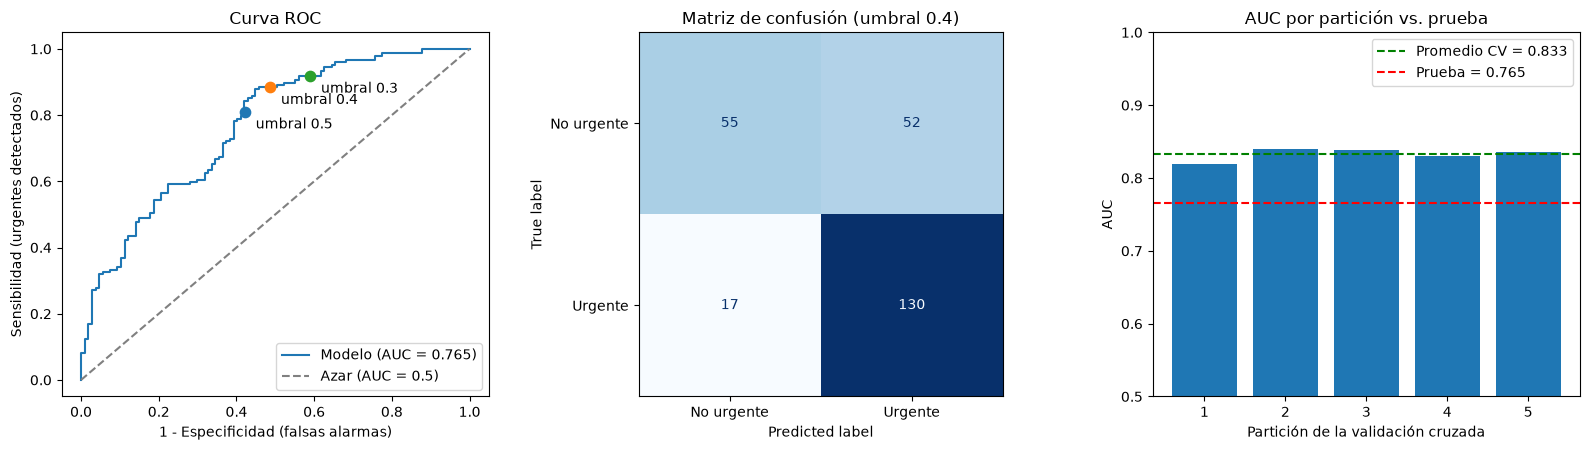

In [144]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

UMBRAL = 0.4

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

# 1) Curva ROC con los umbrales marcados
fpr, tpr, _ = roc_curve(y_test, proba)
ax[0].plot(fpr, tpr, label=f"Modelo (AUC = {roc_auc_score(y_test, proba):.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0.5)")
for u in [0.5, 0.4, 0.3]:
    mu = metricas(u)
    ax[0].scatter(1 - mu["espec"], mu["sens"], s=55, zorder=3)
    ax[0].annotate(f"umbral {u}", (1 - mu["espec"], mu["sens"]), textcoords="offset points", xytext=(8, -12))
ax[0].set_xlabel("1 - Especificidad (falsas alarmas)")
ax[0].set_ylabel("Sensibilidad (urgentes detectados)")
ax[0].set_title("Curva ROC")
ax[0].legend(loc="lower right")

# 2) Matriz de confusión con el umbral elegido
ConfusionMatrixDisplay.from_predictions(
    y_test, (proba >= UMBRAL).astype(int),
    display_labels=["No urgente", "Urgente"], cmap="Blues", ax=ax[1], colorbar=False)
ax[1].set_title(f"Matriz de confusión (umbral {UMBRAL})")

# 3) Estabilidad: AUC por partición frente al AUC de prueba
ax[2].bar(range(1, 6), auc_cv, color="#1f77b4")
ax[2].axhline(auc_cv.mean(), color="green", ls="--", label=f"Promedio CV = {auc_cv.mean():.3f}")
ax[2].axhline(roc_auc_score(y_test, proba), color="red", ls="--", label=f"Prueba = {roc_auc_score(y_test, proba):.3f}")
ax[2].set_ylim(0.5, 1)
ax[2].set_xlabel("Partición de la validación cruzada")
ax[2].set_ylabel("AUC")
ax[2].set_title("AUC por partición vs. prueba")
ax[2].legend()

plt.tight_layout()
plt.show()

### Evaluación en el conjunto de prueba

**Curva ROC.** El modelo alcanza un AUC de **0.765** en el conjunto de prueba (254 pacientes), claramente por encima del azar (0.5). Con el umbral 0.4 el modelo opera en un punto intermedio: detecta la mayoría de los urgentes sin elevar las falsas alarmas tanto como con 0.3.

**Matriz de confusión (umbral 0.4).**

| | Predicho: no urgente | Predicho: urgente |
|---|---|---|
| **Real: no urgente** | 55 | 52 |
| **Real: urgente** | 17 | 130 |

- Sensibilidad: 130 / 147 = **0.884** (se detectan 88 % de los urgentes; se pierden 17).
- Especificidad: 55 / 107 = **0.514** (52 falsas alarmas).

La especificidad en prueba (0.514) es algo menor que la obtenida con predicciones fuera de muestra en entrenamiento (0.571); es el mismo orden de magnitud y refleja la variabilidad de una muestra pequeña. El modelo prioriza no perder pacientes urgentes, a costa de revisar casos que luego resultan no urgentes.

**Estabilidad (validación cruzada vs. prueba).** El AUC por partición es muy parecido entre sí (≈ 0.82–0.84, promedio **0.833**), pero el AUC de prueba (**0.765**) es menor. Se interpretan así:

- Las 5 particiones comparten gran parte de los datos de entrenamiento, por lo que no son independientes: la desviación entre ellas (± 0.005) subestima la incertidumbre real.
- El conjunto de prueba es pequeño (147 urgentes y 107 no urgentes), de modo que su AUC tiene un margen de error de alrededor de ± 0.03.
- Por eso se reportan ambos valores y se toma el de prueba como la estimación más conservadora del desempeño esperado.

### Análisis por subgrupos (umbral 0.4, conjunto de prueba)

| Subgrupo | n | Urgentes | Sensibilidad | Especificidad | Urgentes perdidos |
|---|---|---|---|---|---|
| Sexo 1 | 119 | 68 | 0.912 | 0.490 | 6 |
| Sexo 2 | 135 | 79 | 0.861 | 0.536 | 11 |
| Menores de 65 | 155 | 81 | 0.815 | 0.581 | 15 |
| Mayores de 65 | 99 | 66 | 0.970 | 0.364 | 2 |
| Hospital 1 | 144 | 78 | 0.897 | 0.576 | 8 |
| Hospital 2 | 110 | 69 | 0.870 | 0.415 | 9 |

- **Sexo y hospital:** las diferencias de sensibilidad son pequeñas y con estos tamaños de muestra caben dentro de la variabilidad esperada; no hay evidencia de sesgo. Cabe recordar que en el hospital 1 la saturación de oxígeno no fue registrada, por lo que cualquier diferencia entre hospitales puede deberse en parte a esa variable ausente.
- **Edad:** es el hallazgo más relevante. El modelo pierde más pacientes urgentes entre los menores de 65 años (15 de 81, cerca del 18 %) que entre los mayores (2 de 66, cerca del 3 %). En sentido contrario, entre los mayores genera más falsas alarmas (especificidad 0.364). Esto es coherente con que la edad empuja al modelo a clasificar como urgentes a los mayores. Se declara como **limitación**: el modelo es menos sensible en pacientes jóvenes y su uso debe acompañarse de criterio clínico, sobre todo en este grupo.
- Los subgrupos tienen pocos pacientes, por lo que estas cifras son orientativas y no concluyentes por sí solas.

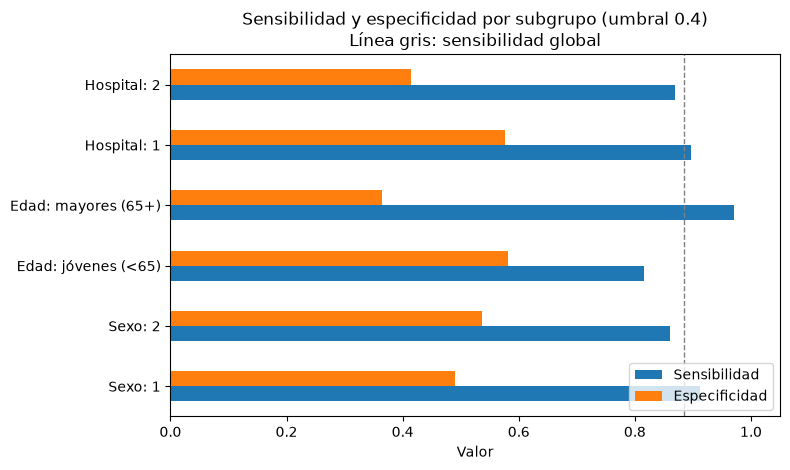

In [145]:
# Sesgo por subgrupo, en barras (umbral 0.4)
nombres = {"Sex": "Sexo", "edad_grupo": "Edad", "Group": "Hospital"}

filas_s = []
for col in ["Sex", "edad_grupo", "Group"]:
    t_ = por_subgrupo(col)
    for _, r_ in t_.iterrows():
        filas_s.append({"subgrupo": f"{nombres[col]}: {str(r_[col]).replace('.0', '')}",
                        "Sensibilidad": r_["sens"], "Especificidad": r_["espec"]})

sesgo = pd.DataFrame(filas_s).set_index("subgrupo")
ax = sesgo.plot.barh(figsize=(8, 4.8))
ax.axvline(metricas(0.4)["sens"], color="gray", ls="--", lw=1)
ax.set_title("Sensibilidad y especificidad por subgrupo (umbral 0.4)\nLínea gris: sensibilidad global")
ax.set_xlim(0, 1.05)
ax.set_xlabel("Valor")
ax.set_ylabel("")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Análisis de errores por subgrupos

- De los 17 pacientes urgentes no detectados, 15 son menores de 65 años (cerca del 88 %).
- La sensibilidad es menor en menores de 65 años (0,815; IC 95 % aprox. 0,72–0,89) que en mayores (0,970; IC 95 % aprox. 0,90–0,99). Los intervalos no se traslapan, por lo que la diferencia probablemente es real y no solo azar.
- En mayores de 65 años la especificidad es baja (0,364): el modelo clasifica como urgentes a muchos pacientes que no lo son. Esto es coherente con que la edad empuja al modelo hacia "urgente".
- Por sexo las diferencias son pequeñas (sensibilidad 0,912 vs 0,861) y caben dentro de la variabilidad esperada con estos tamaños de muestra.
- Por hospital la sensibilidad es parecida (0,897 vs 0,870), pero la especificidad difiere más (0,576 vs 0,415). Con subgrupos de 110 y 144 pacientes no se puede concluir que la diferencia sea real, aunque conviene vigilarla. Además, en el hospital 1 la saturación de oxígeno no fue registrada, lo que podría explicar parte de la diferencia.

**Conclusión:** el modelo tiene más dificultad para detectar pacientes urgentes menores de 65 años, y esa limitación parece real. En mayores detecta casi todas las urgencias, pero genera más falsas alarmas. Las diferencias por sexo y hospital no son concluyentes. Los subgrupos son pequeños, por lo que las cifras deben leerse como orientativas.

### Importancia de las variables

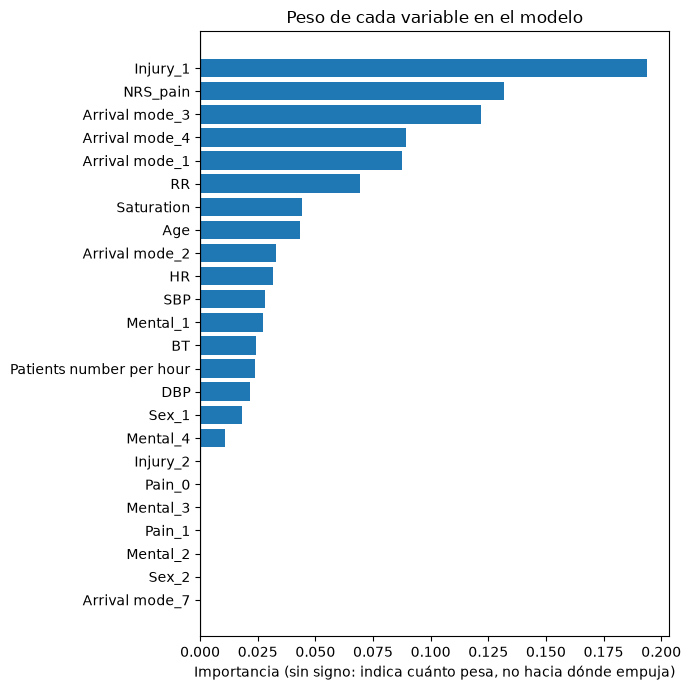

Posición de Age según el tamaño absoluto de su peso: 8 de 24
Las 5 variables con mayor peso: ['Injury_1', 'NRS_pain', 'Arrival mode_3', 'Arrival mode_4', 'Arrival mode_1']


In [146]:
# ¿Qué variables pesan más en el modelo?
clf_final = modelo.named_steps["clf"]
nombres_vars = [n.replace("num__", "").replace("cat__", "")
                for n in modelo.named_steps["pre"].get_feature_names_out()]

if hasattr(clf_final, "coef_"):
    valores = np.ravel(clf_final.coef_)
    etiqueta = "Coeficiente (rojo: empuja a urgente, azul: a no urgente)"
    con_signo = True
elif hasattr(clf_final, "feature_importances_"):
    valores = clf_final.feature_importances_
    etiqueta = "Importancia (sin signo: indica cuánto pesa, no hacia dónde empuja)"
    con_signo = False
else:
    valores = None

if valores is None:
    print("El modelo elegido no expone pesos por variable; se omite esta gráfica.")
else:
    coef = pd.Series(valores, index=nombres_vars).sort_values()
    colores = (["#d62728" if v_ > 0 else "#1f77b4" for v_ in coef.values]
               if con_signo else "#1f77b4")

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.barh(coef.index, coef.values, color=colores)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title("Peso de cada variable en el modelo")
    ax.set_xlabel(etiqueta)
    plt.tight_layout()
    plt.show()

    orden_abs = coef.abs().sort_values(ascending=False).index.tolist()
    if "Age" in orden_abs:
        print("Posición de Age según el tamaño absoluto de su peso:",
              orden_abs.index("Age") + 1, "de", len(orden_abs))
    print("Las 5 variables con mayor peso:", orden_abs[:5])

### Importancia de las variables

- Las cinco variables con mayor peso son, en este orden, `Injury_1`, `NRS_pain`, `Arrival mode_3`, `Arrival mode_4` y `Arrival mode_1`.
- Tres de las cinco son categorías del modo de llegada. Como la codificación one-hot reparte esta variable en varias columnas, su peso conjunto es mayor que el de cada barra por separado.
- `Age` ocupa la posición 8 de 24, por lo que tiene un peso moderado y no es la variable dominante.
- La importancia indica cuánto contribuye cada variable al modelo, pero no muestra si aumenta o disminuye la probabilidad de clasificar a un paciente como urgente. Tampoco implica causalidad, y variables correlacionadas entre sí (por ejemplo, SBP y DBP) se reparten el peso.

**Conclusión:** el modelo se apoya principalmente en la presencia de lesión, el nivel de dolor y el modo de llegada al hospital, y en menor medida en variables clínicas como la edad. Esto es coherente con que el triaje depende de la presentación del paciente, pero no permite afirmar el sentido del efecto de cada variable.

---
## Umbral de caso crítico (R20)

A diferencia del umbral de 0.4, que clasifica a los pacientes como urgentes o no urgentes, el umbral crítico determina cuándo activar una alerta para el médico.

Para justificarlo, se analiza qué proporción de los pacientes que superan distintos umbrales pertenece a las categorías KTAS 1 y 2, correspondientes a los niveles de mayor gravedad.

In [147]:
ktas_test = ktas.loc[X_test.index]
graves = (ktas_test <= 2)

filas = []
for u in [0.6, 0.7, 0.8, 0.9]:
    marcados = proba >= u
    filas.append({"umbral": u,
                  "marcados": int(marcados.sum()),
                  "% realmente KTAS 1-2": round(graves[marcados].mean(), 3) if marcados.sum() else None,
                  "% de los KTAS 1-2 que captura": round(marcados[graves].mean(), 3)})
print(f"KTAS 1-2 en prueba: {int(graves.sum())} de {len(graves)}")
print(pd.DataFrame(filas).to_string())

KTAS 1-2 en prueba: 52 de 254
   umbral  marcados  % realmente KTAS 1-2  % de los KTAS 1-2 que captura
0     0.6       134                 0.254                          0.654
1     0.7       104                 0.298                          0.596
2     0.8        67                 0.373                          0.481
3     0.9        31                 0.516                          0.308


In [148]:
for u in [0.8, 0.9]:
    m = proba >= u
    print(u, "| urgentes entre los marcados:", round(y_test[m].mean(), 3),
          "| no urgentes marcados:", int((y_test[m] == 0).sum()))

0.8 | urgentes entre los marcados: 0.821 | no urgentes marcados: 12
0.9 | urgentes entre los marcados: 0.903 | no urgentes marcados: 3


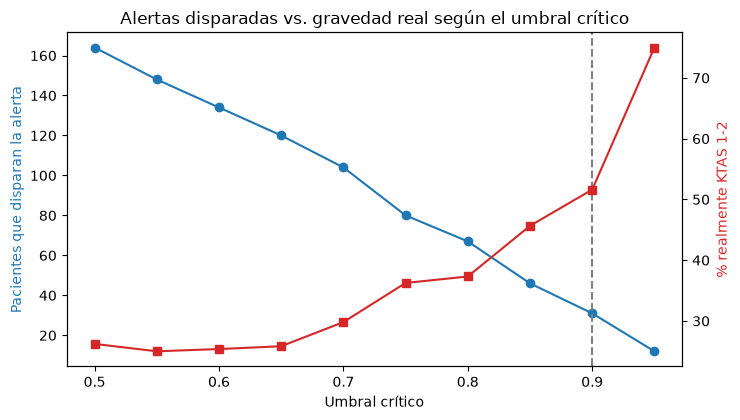

In [149]:
# Umbral crítico: cuántas alertas saltan y qué tan graves son
us = np.arange(0.5, 0.96, 0.05)
n_marc = [int((proba >= u).sum()) for u in us]
pct_graves = [graves.values[proba >= u].mean() * 100 if (proba >= u).sum() else np.nan for u in us]

fig, ax1 = plt.subplots(figsize=(7.5, 4.3))
ax1.plot(us, n_marc, "o-", color="#1f77b4")
ax1.set_xlabel("Umbral crítico")
ax1.set_ylabel("Pacientes que disparan la alerta", color="#1f77b4")
ax2 = ax1.twinx()
ax2.plot(us, pct_graves, "s-", color="#d62728")
ax2.set_ylabel("% realmente KTAS 1-2", color="#d62728")
ax1.axvline(0.9, color="gray", ls="--")
plt.title("Alertas disparadas vs. gravedad real según el umbral crítico")
plt.tight_layout()
plt.show()

In [150]:
graves_idx = graves.values
print("KTAS 1-2 marcados con umbral 0.4:", int((proba[graves_idx] >= 0.4).sum()), "de", int(graves_idx.sum()))

KTAS 1-2 marcados con umbral 0.4: 46 de 52


### Umbral crítico

- Con un umbral de **0,9**, la alerta se activa en 31 de los 254 pacientes de prueba (12 %): 28 son urgentes (90 %) y 3 no urgentes.
- De estas 31 alertas, 16 corresponden a KTAS 1–2 (51,6 %), frente a una proporción base de 20,5 % (52 de 254) en el conjunto de prueba. La alerta es entonces más del doble de selectiva que el azar. Captura el 30,8 % de los pacientes KTAS 1–2.
- Con 0,8 la alerta se activaría en 67 pacientes (26 %), con 12 no urgentes. Capturaría casi la mitad de los KTAS 1–2 (48,1 %), pero a costa de 36 alertas adicionales para detectar unos 9 casos graves más.
- Se mantiene **0,9** para limitar la cantidad de alertas y reducir el riesgo de que el personal termine ignorándolas.
- Los pacientes graves que no alcanzan el umbral crítico siguen siendo detectados por el umbral general de 0,4, que identifica a 46 de los 52 pacientes KTAS 1–2 (88,5 %).
- El umbral de 0,9 se eligió con predicciones fuera de muestra sobre el entrenamiento; este análisis en el conjunto de prueba lo verifica, no lo ajusta. Con solo 31 alertas, los porcentajes son aproximados.

**Conclusión:** el umbral de 0,9 genera alertas críticas selectivas (alrededor de la mitad son KTAS 1–2), mientras que el umbral de 0,4 mantiene la detección amplia de pacientes urgentes. Las alertas críticas no pretenden capturar todos los casos graves, sino priorizar los de mayor probabilidad.

---
### Guardar el modelo

Se guarda el pipeline entrenado con `joblib`, incluyendo el preprocesamiento y el modelo entrenado. También se almacenan la versión, las métricas, el umbral y la fecha en un diccionario.

Así, el servicio `ml` puede cargar el modelo al iniciar sin reentrenarlo, y el endpoint `GET /modelo` puede consultar su información.

In [151]:
import xgboost

m = metricas(0.4)

paquete = {
    "modelo": modelo,
    "version": "1.1",
    "algoritmo": "XGBoost",
    "nombre_modelo": elegido_sup,
    "umbral": 0.4,
    "umbral_critico": 0.9,
    "columnas_num": cols_num,
    "columnas_cat": cols_cat,
    "metricas": {
        "auc_prueba": round(float(roc_auc_score(y_test, proba)), 3),
        "auc_cv": round(float(auc_cv.mean()), 3),
        "sensibilidad": float(m["sens"]), "especificidad": float(m["espec"]),
        "precision": float(m["prec"]), "f1": float(m["f1"]),
        "matriz_confusion": {"TN": int(m["TN"]), "FP": int(m["FP"]),
                             "FN": int(m["FN"]), "TP": int(m["TP"])},
    },
    "fecha": datetime.now().isoformat(timespec="seconds"),
    "sklearn": sklearn.__version__,
    "xgboost": xgboost.__version__,
}

RUTA_ML = ruta_csv.parent.parent   # carpeta ml/, calculada desde la ruta del CSV (sin ruta fija)
(RUTA_ML / "modelo").mkdir(exist_ok=True)

joblib.dump(paquete, RUTA_ML / "modelo" / "ktas_modelo.joblib")
print(paquete["algoritmo"], paquete["sklearn"], paquete["xgboost"])
print(paquete["metricas"])

XGBoost 1.5.2 3.4.1
{'auc_prueba': 0.765, 'auc_cv': 0.833, 'sensibilidad': 0.884, 'especificidad': 0.514, 'precision': 0.714, 'f1': 0.79, 'matriz_confusion': {'TN': 55, 'FP': 52, 'FN': 17, 'TP': 130}}


### Métricas del modelo

El modelo XGBoost obtiene un AUC de **0.765** en prueba y de **0.833** en validación cruzada. Con un umbral de 0.4, alcanza una sensibilidad de **0.884**, detectando el 88.4 % de los pacientes urgentes, y una especificidad de **0.514**. La precisión es de **0.714** y el F1 de **0.790**.

La matriz de confusión registra **130 verdaderos positivos (TP), 55 verdaderos negativos (TN), 52 falsos positivos (FP) y 17 falsos negativos (FN)**.

---

### Prueba del servicio de predicción

**1. Consultar la información del modelo**

Verifica que el modelo esté cargado y que sus métricas y umbrales estén disponibles.

```powershell
docker compose exec ml python -c "import urllib.request as u; print(u.urlopen('http://localhost:8001/modelo').read().decode())"
```

**2. Enviar un paciente de prueba**

Envía datos de ejemplo al endpoint de predicción.

```powershell
docker compose exec ml python -c "import json,urllib.request as u; d={'id_seudonimo':'p-001','sexo':2,'edad':75,'pacientes_por_hora':5,'modo_llegada':3,'lesion':1,'mental':1,'dolor':1,'nrs_dolor':8,'sbp':85,'dbp':50,'fc':125,'fr':26,'temperatura':38.5,'saturacion':86}; r=u.Request('http://localhost:8001/predecir',json.dumps(d).encode(),{'Content-Type':'application/json'}); print(u.urlopen(r).read().decode())"
```

**3. Resultado esperado**

- Probabilidad: muy alta (cercana a 1). El valor exacto cambia con XGBoost: 0.9988
- Clasificación: urgente (`true`).
- Caso crítico: `true`.
- Nivel: `critico`.
- Versión del modelo: `2.1`.

**4. Comprobar casos de diferente gravedad.**

El primer paciente de prueba tiene 75 años, saturación de oxígeno del 86 %, presión arterial baja y frecuencia cardíaca elevada. El modelo devuelve una probabilidad muy alta y lo clasifica como `critico`, activando la alerta.

También se puede probar el otro extremo con un paciente joven y signos vitales normales para comprobar si el modelo lo clasifica como `no urgente`. Así se verifica que el servicio responde ante perfiles clínicos diferentes.

---
### `POST /entrenar`

Se traslada el código de entrenamiento del cuaderno a un archivo `entrenar.py`, integrando la limpieza, la separación de datos, el pipeline y el guardado del modelo para que el servicio pueda reentrenarlo cuando se solicite.

Hay dos aspectos importantes:

- **Reutilización:** mantener las mismas reglas de preprocesamiento y entrenamiento del cuaderno.
- **Integración:** permitir que el endpoint `POST /entrenar` ejecute el proceso y guarde el nuevo modelo para su uso posterior.

----

## AGRUPAMIENTO

## Preparamos y buscar el número de grupos (codo + silueta)

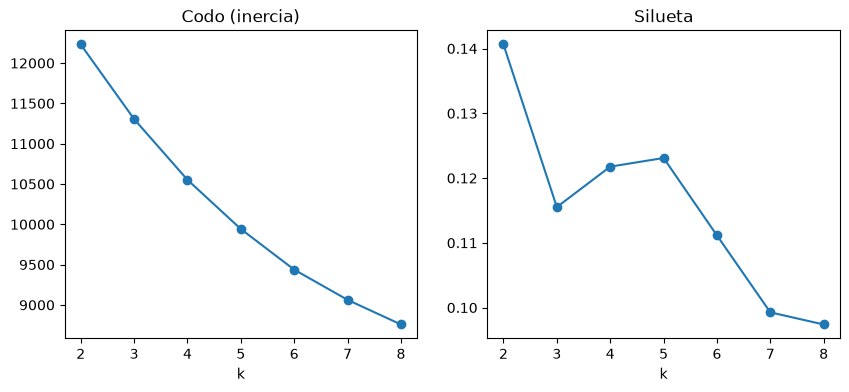

{2: np.float64(0.141), 3: np.float64(0.116), 4: np.float64(0.122), 5: np.float64(0.123), 6: np.float64(0.111), 7: np.float64(0.099), 8: np.float64(0.097)}


In [152]:

# Preprocesamiento del modelo (mediana , escala , one-hot) sobre todos los pacientes reales
Z = clone(pre).fit_transform(X)   # clone: no reajusta el 'pre' que usa el modelo final
if hasattr(Z, "toarray"):
    Z = Z.toarray()

ks = range(2, 9)
inercia, silueta = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inercia.append(km_k.inertia_)
    silueta.append(silhouette_score(Z, km_k.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inercia, marker="o"); ax[0].set_title("Codo (inercia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, silueta, marker="o"); ax[1].set_title("Silueta"); ax[1].set_xlabel("k")
plt.show()
print(dict(zip(ks, np.round(silueta, 3))))

### Interpretación del agrupamiento

- **Método del codo:** la inercia disminuye progresivamente, sin un punto de quiebre claro que permita elegir un valor de \(k\).
- **Silueta:** los valores son bajos (0.097–0.141), lo que indica poca separación entre los grupos.
- **Selección de \(k\):** como el codo y la silueta no permiten una elección clara, se consideran también la estabilidad de los grupos, su interpretabilidad clínica y su utilidad para analizar la urgencia y los errores del modelo.

Por tanto, el agrupamiento se plantea como una **segmentación descriptiva de pacientes**, no como evidencia de grupos naturales claramente diferenciados.

---
# Comparación de algoritmos de agrupamiento

En aprendizaje no supervisado **no existe un «AUC»**: no hay respuesta correcta contra la cual medir. Por eso se combinan cuatro criterios:

| Criterio | Qué mide | Se busca |
|---|---|---|
| **Silueta** | Qué tan separados están los grupos (−1 a 1) | Mayor |
| **Davies-Bouldin** | Cuánto se parecen los grupos entre sí | Menor |
| **ARI** frente a K-means | Cuánto coincide con otro método, sin importar cómo se numeren los grupos | Informativo |
| **Utilidad para el sistema (R07)** | Al menos 2 grupos y poder asignar a un paciente nuevo a su grupo | Obligatorio |

Se comparan cuatro algoritmos, cada uno con supuestos distintos: **K-means** (grupos redondos, pertenencia dura), **jerárquico de Ward** (árbol de uniones), **GMM** (campanas gaussianas con pertenencia suave) y **DBSCAN** (grupos por densidad, detecta ruido).

**Advertencia de honestidad.** La silueta y Davies-Bouldin favorecen a K-means *por construcción*, porque K-means optimiza justamente la compacidad de grupos redondos. Por eso estas métricas **orientan, pero no deciden solas**: pesan también la interpretación clínica y la utilidad para el sistema. Los datos mezclan variables numéricas y one-hot, así que GMM usa covarianza diagonal (con 1.267 pacientes y muchas columnas, la covarianza completa es inestable).

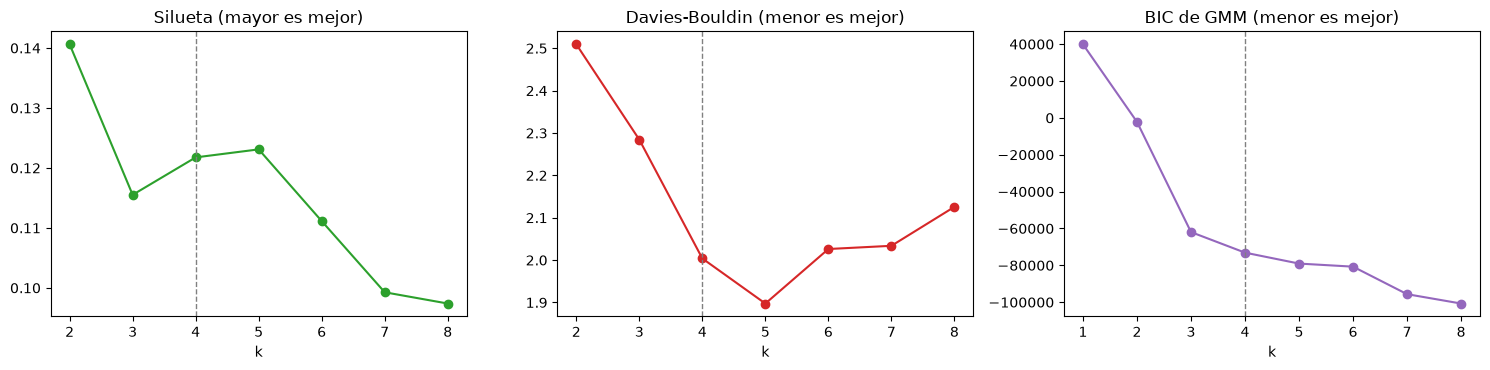

,silueta,davies_bouldin
k,,
2,0.141,2.509
3,0.116,2.284
4,0.122,2.004
5,0.123,1.898
6,0.111,2.026
7,0.099,2.034
8,0.097,2.126


In [153]:
from sklearn.metrics import davies_bouldin_score
from sklearn.mixture import GaussianMixture

# Tres criterios para elegir k (K-means) y el BIC de GMM
filas = []
for k_ in range(2, 9):
    etiq_ = KMeans(n_clusters=k_, n_init=10, random_state=42).fit_predict(Z)
    filas.append({"k": k_, "silueta": silhouette_score(Z, etiq_),
                  "davies_bouldin": davies_bouldin_score(Z, etiq_)})
criterios_k = pd.DataFrame(filas).set_index("k")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    bic = {k_: GaussianMixture(n_components=k_, covariance_type="diag", n_init=3, random_state=42).fit(Z).bic(Z)
           for k_ in range(1, 9)}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
criterios_k["silueta"].plot(ax=ax[0], marker="o", color="tab:green", title="Silueta (mayor es mejor)")
criterios_k["davies_bouldin"].plot(ax=ax[1], marker="o", color="tab:red", title="Davies-Bouldin (menor es mejor)")
pd.Series(bic).plot(ax=ax[2], marker="o", color="tab:purple", title="BIC de GMM (menor es mejor)")
for a_ in ax:
    a_.set_xlabel("k")
    a_.axvline(4, color="gray", ls="--", lw=1)
plt.tight_layout()
plt.show()
criterios_k.round(3)

Los criterios no coinciden en un único k: la silueta es máxima en k = 2, Davies-Bouldin en k = 5 y el BIC deja de mejorar de forma marcada a partir de k = 3. En todos los casos los valores son modestos (silueta < 0,15), lo que indica que los pacientes forman una nube continua más que grupos bien separados. Por eso el k no se elige solo por una métrica, sino combinándola con la estabilidad de los grupos y su interpretación clínica. El BIC se toma como evidencia débil, porque con variables one-hot la covarianza diagonal tiende a seguir mejorando al aumentar k.

In [154]:
from sklearn.metrics import adjusted_rand_score

rng_b = np.random.default_rng(42)
filas = []
for k_ in range(2, 9):
    ref = KMeans(n_clusters=k_, n_init=10, random_state=42).fit(Z)
    aris = []
    for _ in range(20):
        idx = rng_b.integers(0, len(Z), len(Z))
        km_b = KMeans(n_clusters=k_, n_init=3, random_state=int(rng_b.integers(1_000_000))).fit(Z[idx])
        aris.append(adjusted_rand_score(ref.labels_, km_b.predict(Z)))
    filas.append({"k": k_, "estabilidad": np.mean(aris), "grupo_mas_pequeno": int(np.bincount(ref.labels_).min())})
estab_k = pd.DataFrame(filas).set_index("k")
estab_k.round(3)

,estabilidad,grupo_mas_pequeno
k,,
2,0.940,556
3,0.808,316
4,0.700,32
5,0.688,31
6,0.642,25
7,0.660,21
8,0.599,22


In [155]:
k3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Z)
k4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(Z)

print(pd.crosstab(k3, k4, rownames=["k = 3"], colnames=["k = 4"]))

# ¿Coinciden k = 3 y k = 4 si se quitan los 6 pacientes del grupo pequeño?
chico = pd.Series(k4).value_counts().idxmin()
sin_extremos = k4 != chico
print("ARI k=3 vs k=4 sin los 6 extremos:",
      round(adjusted_rand_score(k3[sin_extremos], k4[sin_extremos]), 3))

k = 4   0    1    2    3
k = 3                   
0       0  300   14    2
1       0    0    0  520
2      32    5  390    4
ARI k=3 vs k=4 sin los 6 extremos: 0.947


In [156]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Z)
d_centro = km3.transform(Z).min(axis=1)          # distancia al centroide más cercano
umbral_atipico = np.percentile(d_centro, 99)
atipico = d_centro > umbral_atipico

extremos = (k4 == chico)                         # los 6 de la celda anterior
print("Pacientes marcados como atípicos:", int(atipico.sum()))
print("De los 6 extremos, marcados:", int((atipico & extremos).sum()), "de", int(extremos.sum()))
print("Silueta k = 3:", round(silhouette_score(Z, km3.labels_), 3))

Pacientes marcados como atípicos: 13
De los 6 extremos, marcados: 7 de 32
Silueta k = 3: 0.116


In [157]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Z)
et = pd.Series(km4.labels_, index=X.index)
sub = et == et.value_counts().idxmin()      # el grupo de 32

comp = X[sub].median(numeric_only=True).to_frame("grupo_pequeño").join(
       X[~sub].median(numeric_only=True).to_frame("resto")).round(1)
print(comp)
print("% urgentes: grupo pequeño", round(y[sub].mean(), 3), "| resto", round(y[~sub].mean(), 3))
print("% sin saturación:", round(X.loc[sub, "Saturation"].isna().mean(), 2))

                          grupo_pequeño  resto
Age                                72.5   56.0
Patients number per hour            8.0    7.0
NRS_pain                            0.0    3.0
SBP                               110.0  130.0
DBP                                80.0   80.0
HR                                100.0   81.0
RR                                 20.0   20.0
BT                                 36.4   36.5
Saturation                         90.0   98.0
Sex                                 2.0    2.0
Arrival mode                        4.0    3.0
Injury                              1.0    1.0
Mental                              1.0    1.0
Pain                                0.0    1.0
% urgentes: grupo pequeño 1.0 | resto 0.568
% sin saturación: 0.0


### Selección del número de clusters

- La silueta es máxima en k = 2 (0,141), pero todos los valores son bajos (0,097–0,141): la separación entre grupos es débil.
- Davies-Bouldin mejora hasta k = 5 (1,898); entre k = 3 y k = 4 pasa de 2,284 a 2,004.
- El BIC del modelo GMM cae marcadamente hasta k = 3 y luego casi se aplana, sin un mínimo claro. Se toma como evidencia débil, porque con variables one-hot la covarianza diagonal tiende a seguir mejorando al aumentar k.
- Los criterios no coinciden en un único k, por lo que no hay un número óptimo evidente.

**Estabilidad (remuestreo bootstrap, ARI):** 0,940 (k = 2), 0,808 (k = 3), 0,700 (k = 4), 0,688 (k = 5). La estabilidad disminuye al aumentar k. Con k = 4 aparece un grupo de solo 32 pacientes, que proviene íntegramente de uno de los grupos de k = 3.

### Elección de k

Se elige **k = 4**. Ningún criterio global señala un k óptimo (silueta máxima en k = 2, Davies-Bouldin en k = 5, BIC sin mínimo claro, todos con valores modestos), por lo que la decisión se apoya en la estabilidad y en la interpretación clínica:

- k = 4 conserva los tres grupos grandes de k = 3 (ARI de 0,947 al compararlos sin el grupo nuevo) y añade un cuarto grupo de **32 pacientes**, que proviene íntegramente de uno de ellos.
- Ese grupo tiene un perfil clínico definido: pacientes mayores (mediana 72,5 años) con saturación baja (mediana 90 %, frente a 98 %), frecuencia cardíaca más alta (100 frente a 81) y sin dolor. **Los 32 son urgentes (100 %)**, frente al 57 % del resto, y todos tienen la saturación registrada, por lo que no es un efecto de la imputación.
- La estabilidad de k = 4 (ARI 0,700) es menor que la de k = 3 (0,808): el costo de separar este subgrupo es una menor reproducibilidad.

**Limitaciones:** el grupo pequeño es poco numeroso (2,5 % de los pacientes) y su estabilidad es moderada. Además, la saturación solo se registró en el hospital 2, por lo que no se puede saber si en el hospital 1 existen pacientes con un perfil similar.

**Conclusión:** k = 4 permite identificar un subgrupo clínicamente relevante y totalmente urgente que k = 3 no separa, a cambio de una estabilidad algo menor.

In [158]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage

K_ELEGIDO = 4
et = {}   # etiquetas de cada algoritmo

# --- K-means, jerárquico y GMM, todos con k = 4 (comparación justa)
et["K-means"] = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=42).fit_predict(Z)
et["Jerárquico (Ward)"] = AgglomerativeClustering(n_clusters=K_ELEGIDO, linkage="ward").fit_predict(Z)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    gmm_c = GaussianMixture(n_components=K_ELEGIDO, covariance_type="diag", n_init=3, random_state=42).fit(Z)
et["GMM"] = gmm_c.predict(Z)
zona_gris = float((gmm_c.predict_proba(Z).max(axis=1) < 0.6).mean() * 100)   # sin grupo claro

# --- DBSCAN: no pide k, pide eps. Se prueban varios eps tomados de la curva de distancias
MIN_MUESTRAS = 2 * len(cols_num + cols_cat)          # regla práctica: 2 x variables originales
dist_vecinos, _ = NearestNeighbors(n_neighbors=MIN_MUESTRAS).fit(Z).kneighbors(Z)
dist_k = np.sort(dist_vecinos[:, -1])
etiq_db, filas_db = {}, []
for q_ in [50, 70, 85, 95]:
    eps_ = float(np.percentile(dist_k, q_))
    e_ = DBSCAN(eps=eps_, min_samples=MIN_MUESTRAS).fit_predict(Z)
    etiq_db[q_] = e_
    filas_db.append({"percentil": q_, "eps": round(eps_, 2),
                     "grupos": len(set(e_[e_ != -1])), "% ruido": round((e_ == -1).mean() * 100, 1)})
print("DBSCAN con distintos eps:")
print(pd.DataFrame(filas_db).to_string(index=False))

# DBSCAN para la tabla: el eps con >= 2 grupos y mejor silueta; si ninguno, un solo grupo + ruido
def _sil(e):
    m_ = e != -1
    return silhouette_score(Z[m_], e[m_])
con_2 = {q_: e_ for q_, e_ in etiq_db.items() if len(set(e_[e_ != -1])) >= 2}
et["DBSCAN"] = con_2[max(con_2, key=lambda q_: _sil(con_2[q_]))] if con_2 else etiq_db[85]

# --- Tabla comparativa
def _tamanos(e):
    v_ = pd.Series(e[e != -1]).value_counts().sort_values(ascending=False)
    return ", ".join(str(int(x_)) for x_ in v_.values)

INFO = {"K-means": (True, "dura"), "Jerárquico (Ward)": (False, "dura"),
        "GMM": (True, "suave"), "DBSCAN": (False, "dura")}
filas = []
for nombre, e_ in et.items():
    ok = e_ != -1
    n_g = len(set(e_[ok]))
    s_, d_ = ((silhouette_score(Z[ok], e_[ok]), davies_bouldin_score(Z[ok], e_[ok])) if n_g >= 2 else (np.nan, np.nan))
    filas.append({"algoritmo": nombre, "grupos": n_g, "tamaños": _tamanos(e_),
                  "silueta": s_, "davies_bouldin": d_,
                  "ARI_vs_Kmeans": adjusted_rand_score(et["K-means"], e_),
                  "% ruido": round((e_ == -1).mean() * 100, 1),
                  "predice_nuevos": INFO[nombre][0], "pertenencia": INFO[nombre][1]})
tabla_nosup = pd.DataFrame(filas).set_index("algoritmo")

# Regla de decisión (fijada de antemano):
#   1) debe cumplir R07: >= 2 grupos y poder asignar pacientes nuevos
#   2) entre los que cumplen, empatan los que están a menos de 0.01 de la mejor silueta
#   3) entre los empatados gana el más simple
ORDEN_SIMPLICIDAD = ["K-means", "GMM", "Jerárquico (Ward)", "DBSCAN"]
elegibles = tabla_nosup[(tabla_nosup["grupos"] >= 2) & (tabla_nosup["predice_nuevos"])]
mejor_sil = elegibles["silueta"].max()
empatados_nosup = elegibles.index[elegibles["silueta"] >= mejor_sil - 0.01].tolist()
elegido_nosup = next(a_ for a_ in ORDEN_SIMPLICIDAD if a_ in empatados_nosup)

print(f"\nPacientes de GMM sin grupo claro (probabilidad máxima < 0.6): {zona_gris:.1f} %")
print(f"Cumplen R07 (>= 2 grupos y asignan pacientes nuevos): {', '.join(elegibles.index)}")
print(f"Empatados en silueta (a menos de 0.01 de la mejor): {', '.join(empatados_nosup)}")
print(f"Elegido según la regla: {elegido_nosup}")
tabla_nosup.round(3)

DBSCAN con distintos eps:
 percentil  eps  grupos  % ruido
        50 2.55       1     12.3
        70 2.80       1      6.1
        85 3.13       1      3.7
        95 3.75       1      1.7

Pacientes de GMM sin grupo claro (probabilidad máxima < 0.6): 0.0 %
Cumplen R07 (>= 2 grupos y asignan pacientes nuevos): K-means, GMM
Empatados en silueta (a menos de 0.01 de la mejor): K-means
Elegido según la regla: K-means


,grupos,tamaños,silueta,davies_bouldin,ARI_vs_Kmeans,% ruido,predice_nuevos,pertenencia
algoritmo,,,,,,,,
K-means,4,"526, 404, 305, 32",0.122,2.004,1.000,0.0,True,dura
Jerárquico (Ward),4,"657, 532, 73, 5",0.136,1.869,0.474,0.0,False,dura
GMM,4,"499, 361, 340, 67",0.047,4.597,0.383,0.0,True,suave
DBSCAN,1,1220,NaN,NaN,0.026,3.7,False,dura


### Comparación de algoritmos de clustering

- **K-means:** silueta 0,122 y Davies-Bouldin 2,004; tamaños: 526, 404, 305 y 32.
- **Ward:** silueta 0,136 y Davies-Bouldin 1,869; tamaños: 657, 532, 73 y 5.
- **GMM:** silueta 0,047 y Davies-Bouldin 4,597; tamaños: 499, 361, 340 y 67. Ningún paciente queda sin grupo claro, aunque esto no garantiza una buena separación.
- **DBSCAN:** identificó un solo grupo para todos los valores de `eps`, con ruido entre 1,7 % y 12,3 %.

Solo K-means y GMM cumplen R07 (identificar al menos dos grupos y asignar pacientes nuevos). Según la regla establecida, se selecciona **K-means**. Las siluetas bajas indican que la separación entre los grupos es débil.

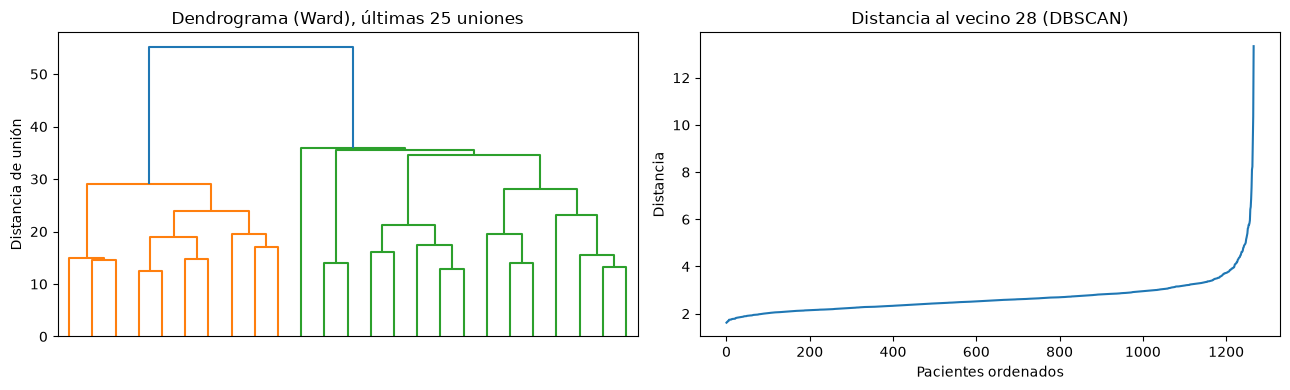

In [159]:
# Dendrograma (jerárquico) y curva de distancias (para elegir eps en DBSCAN)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dendrogram(linkage(Z, method="ward"), truncate_mode="lastp", p=25, no_labels=True, ax=ax[0])
ax[0].set_title("Dendrograma (Ward), últimas 25 uniones")
ax[0].set_ylabel("Distancia de unión")
ax[1].plot(dist_k)
ax[1].set_title(f"Distancia al vecino {MIN_MUESTRAS} (DBSCAN)")
ax[1].set_xlabel("Pacientes ordenados")
ax[1].set_ylabel("Distancia")
plt.tight_layout()
plt.show()

### Dendrograma y distancias

- El dendrograma muestra una separación marcada entre dos ramas principales (izquierda y derecha), lo que sugiere un corte óptimo para 2 clusters.


- La curva de distancias al vecino 28 (DBSCAN) presenta un cambio de pendiente (*codo*) alrededor de una distancia de 4 a 4.5, indicando una densidad de datos continua con pocos pacientes atípicos.

## Describir cada grupo

In [160]:
k = 4  
km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
res_c = X.copy()
res_c["cluster"] = km.labels_
res_c["urgente"] = y
res_c["KTAS"] = ktas.loc[X.index]

print(res_c.groupby("cluster").agg(
    n=("urgente", "size"), edad=("Age", "mean"), sbp=("SBP", "median"),
    fc=("HR", "median"), sat=("Saturation", "median"),
    nrs=("NRS_pain", "mean"), pct_urgente=("urgente", "mean")
).round(2))

           n   edad    sbp     fc   sat   nrs  pct_urgente
cluster                                                   
0         32  68.28  110.0  100.0  90.0  0.78         1.00
1        305  57.06  161.0   86.0  98.0  2.40         0.58
2        404  58.56  121.0   82.0  98.0  0.00         0.69
3        526  48.87  120.0   80.0  98.0  4.13         0.46




### Interpretación de los Clusters ($k = 4$)

A continuación se presenta la caracterización de los 4 clusters obtenidos mediante K-Means, utilizando las métricas centrales de las variables clínicas y hemodinámicas del dataset:

| Cluster | $n$ | Edad (media) | SBP (mediana) | HR / FC (mediana) | SatO2 (mediana) | NRS Pain (media) | % Urgente |
| --- | --- | --- | --- | --- | --- | --- | --- |
| **0** | 32 | 68.28 | 110.0 | 100.0 | 90.0 | 0.78 | **100%** |
| **1** | 305 | 57.06 | 161.0 | 86.0 | 98.0 | 2.40 | **58%** |
| **2** | 404 | 58.56 | 121.0 | 82.0 | 98.0 | 0.00 | **69%** |
| **3** | 526 | 48.87 | 120.0 | 80.0 | 98.0 | 4.13 | **46%** |

---

### Análisis de perfiles clínicos

* **Cluster 0 — Pacientes críticos con compromiso sistémico/respiratorio ($n = 32$):**
* **Perfil:** Pacientes de mayor edad (`Age` media: 68.3 años) que presentan taquicardia (`HR` mediana: 100 bpm) y desaturación marcada (`SatO2` mediana: 90%), con una evaluación de dolor baja (`NRS_pain` media: 0.78).
* **Relevancia clínica:** Muestra una tasa de urgencia del **100%**. Aunque el paciente no manifieste dolor severo, los signos vitales alterados (frecuencia cardíaca y saturación) justifican su clasificación prioritaria.


* **Cluster 1 — Pacientes con compromiso hemodinámico / Presión severa ($n = 305$):**
* **Perfil:** Adultos de edad media (`Age` media: 57.1 años) caracterizados por cifras elevadas de presión arterial sistólica (`SBP` mediana: 161 mmHg) y dolor moderado-bajo (`NRS_pain` media: 2.40).
* **Relevancia clínica:** Agrupa cuadros compatibles con urgencias o crisis hipertensivas, registrando una tasa de urgencia del 58%.


* **Cluster 2 — Pacientes de riesgo sin sintomatología de dolor ($n = 404$):**
* **Perfil:** Pacientes de edad intermedia (`Age` media: 58.6 años) con constantes vitales dentro de rangos estables (`SBP`: 121 mmHg, `HR`: 82 bpm) pero con ausencia total de dolor registrado (`NRS_pain` media: 0.00).
* **Relevancia clínica:** A pesar de no reportar dolor, el **69% de estos pacientes resulta ser urgente**, lo que evidencia la presencia de motivos de consulta principales (`Chief_complain`) u otras alteraciones no dolorosas de alta gravedad (ej. eventos cerebrovasculares, disnea o sintomatología metabólica).


* **Cluster 3 — Pacientes jóvenes con dolor agudo no crítico ($n = 526$):**
* **Perfil:** Es el grupo más numeroso del dataset, conformado por los pacientes más jóvenes (`Age` media: 48.9 años), signos vitales hemodinámicamente estables y la intensidad de dolor más alta reportada por enfermería (`NRS_pain` media: 4.13).
* **Relevancia clínica:** Presenta la menor tasa de urgencia (46%), reflejando que los cuadros de dolor agudo aislado sin alteración de constantes vitales suelen corresponder a baja o menor prioridad de triaje.

### Pacientes agrupados - grafico PCA

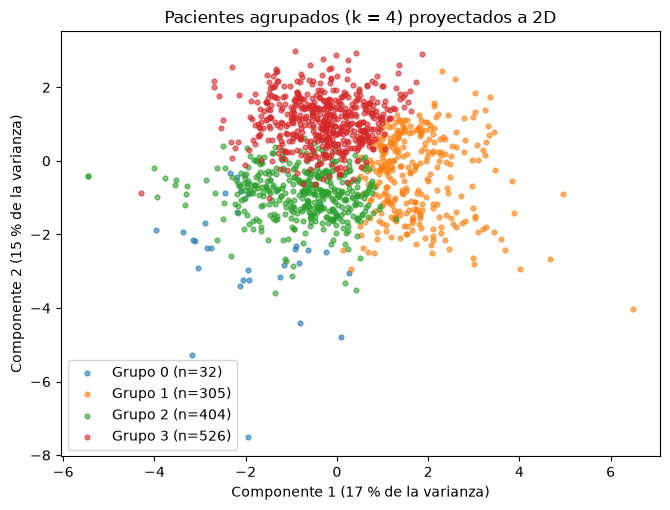

In [161]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42).fit(Z)
Z2 = pca.transform(Z)

fig, ax = plt.subplots(figsize=(6.8, 5.2))
for c_ in sorted(res_c["cluster"].unique()):
    m_ = (res_c["cluster"].values == c_)
    ax.scatter(Z2[m_, 0], Z2[m_, 1], s=12, alpha=0.6, label=f"Grupo {c_} (n={int(m_.sum())})")
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]*100:.0f} % de la varianza)")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]*100:.0f} % de la varianza)")
ax.set_title("Pacientes agrupados (k = 4) proyectados a 2D")
ax.legend()
plt.tight_layout()
plt.show()


####  Visualización mediante PCA (2D)
* **Proyección y Varianza Explicada:** La reducción de dimensionalidad a dos componentes principales retiene el **$32\%$ de la varianza total** ($17\%$ PC1 + $15\%$ PC2)
* **Interpretación espacial:** 
  * El **Grupo 0** ($n=32$) se diferencia hacia la región inferior de la proyección, confirmando su naturaleza atípica y diferenciada
  * El **Grupo 1** ($n=305$) se desplaza a lo largo de PC1, correlacionándose con los niveles elevados de presión arterial
  * La superposición observada entre algunos puntos refleja la alta dimensionalidad subyacente de las variables clínicas

---



## Perfil de cada grupo frente a la cohorte

Para interpretar un grupo no basta con ver sus promedios: hay que compararlos con los de **todos** los pacientes. La tabla siguiente muestra, para cada variable numérica, cuántas desviaciones estándar está cada grupo por encima (rojo) o por debajo (azul) del promedio general.

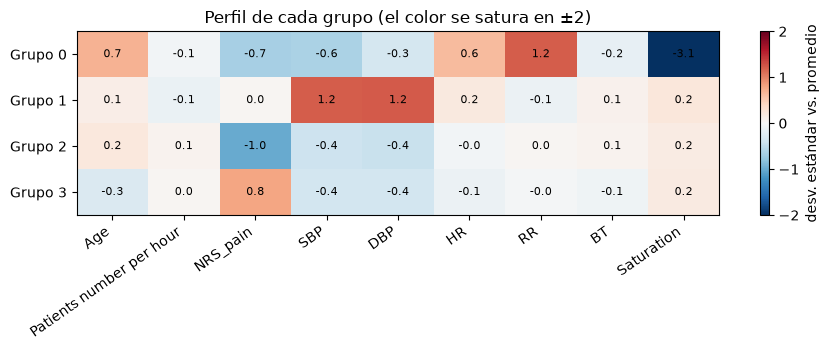

In [162]:
# Perfil de cada grupo en desviaciones estándar respecto al promedio de toda la cohorte
perfil_z = (res_c.groupby("cluster")[cols_num].mean() - X[cols_num].mean()) / X[cols_num].std()

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(perfil_z, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(cols_num)))
ax.set_xticklabels(cols_num, rotation=35, ha="right")
ax.set_yticks(range(len(perfil_z)))
ax.set_yticklabels([f"Grupo {c_}" for c_ in perfil_z.index])
for i_ in range(perfil_z.shape[0]):
    for j_ in range(perfil_z.shape[1]):
        ax.text(j_, i_, f"{perfil_z.iloc[i_, j_]:.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="desv. estándar vs. promedio")
ax.set_title("Perfil de cada grupo (el color se satura en ±2)")
plt.tight_layout()
plt.show()



* **Grupo 0:** Desaturación severa ($\text{-3.1}\sigma$) y taquipnea ($\text{RR +1.2}$) con dolor por debajo de la media ($\text{-0.7}$).


* **Grupo 1:** Marcado incremento en la presión arterial sistólica y diastólica ($\text{+1.2}\sigma$).


* **Grupo 2:** Caracterizado por una profunda ausencia de dolor reportado ($\text{NRS -1.0}$).


* **Grupo 3:** Pacientes más jóvenes ($\text{Age -0.3}$) que experimentan niveles de dolor superiores al promedio ($\text{+0.8}$).

In [163]:
# Etiqueta y gravedad por grupo (los grupos se formaron SIN la etiqueta; recién ahora se mira)
dist_ktas = pd.crosstab(res_c["cluster"], res_c["KTAS"], normalize="index").round(2)
dist_ktas.columns = [f"KTAS {c_}" for c_ in dist_ktas.columns]
dist_ktas["% urgentes (KTAS 1-3)"] = (res_c.groupby("cluster")["urgente"].mean() * 100).round(1)
dist_ktas["% KTAS 1-2"] = ((res_c["KTAS"] <= 2).groupby(res_c["cluster"]).mean() * 100).round(1)
dist_ktas

,KTAS 1,KTAS 2,KTAS 3,KTAS 4,KTAS 5,% urgentes (KTAS 1-3),% KTAS 1-2
cluster,,,,,,,
0,0.12,0.53,0.34,0.00,0.00,100.0,65.6
1,0.01,0.19,0.39,0.37,0.05,58.4,19.7
2,0.04,0.19,0.45,0.23,0.08,69.1,23.8
3,0.00,0.13,0.33,0.49,0.05,46.4,13.1




* **Grupo 0:** Concentra la máxima gravedad; el **100%** de los pacientes son urgentes (KTAS 1-3) y un **65.6%** se ubica en alta prioridad (KTAS 1-2).


* **Grupo 1:** Presenta un **58.4%** de urgencias, repartido principalmente entre los niveles KTAS 3 y KTAS 4.


* **Grupo 2:** Registra un **69.1%** de urgencias, destacando una alta proporción en el nivel KTAS 3 (**0.45**).


* **Grupo 3:** Es el grupo con menor gravedad general; el **46.4%** son urgentes y predomina marcadamente en el nivel no urgente KTAS 4 (**0.49**).

In [164]:
# Nombre de cada grupo ASIGNADO POR CÓDIGO según su perfil.
# Los números (0, 1, 2, 3) dependen de la inicialización de K-means y pueden cambiar con otra
# versión de scikit-learn; el perfil no.
resumen_g = res_c.groupby("cluster").agg(
    sat=("Saturation", "median"), sbp=("SBP", "median"), nrs=("NRS_pain", "mean"))

c_hipox = resumen_g["sat"].idxmin()                    # la saturación más baja
resto = resumen_g.drop(c_hipox)
c_hta = resto["sbp"].idxmax()                          # la presión sistólica más alta de los demás
resto = resto.drop(c_hta)
c_sin_dolor = resto["nrs"].idxmin()                    # el menor dolor de los que quedan
c_general = resto.drop(c_sin_dolor).index[0]           # el que sobra

NOMBRES = {
    c_hipox: "Hipoxemia severa con frecuencia respiratoria alta",
    c_hta: "Presión arterial alta",
    c_sin_dolor: "Sin dolor y con alta proporción de urgentes",
    c_general: "Grupo general (dolor por encima del promedio, signos vitales normales)",
}
pd.Series(NOMBRES).sort_index().to_frame("nombre")

,nombre
0,Hipoxemia severa con frecuencia respiratoria alta
1,Presión arterial alta
2,Sin dolor y con alta proporción de urgentes
3,"Grupo general (dolor por encima del promedio, ..."


### Del grupo a la decisión

Interpretar los grupos «en términos de la problemática» (R07) es decir qué cambia, para quien atiende, saber que un paciente pertenece a cada uno.

| Grupo | Qué se observa | Qué apoya |
|---|---|---|
| **Hipoxemia severa con frecuencia respiratoria alta** | Saturación muy baja, frecuencia respiratoria alta y mayor edad; todos urgentes. Son pocos pacientes | Priorizar por saturación y respiración. El modelo no falla aquí, pero con tan pocos casos no se puede generalizar |
| **Presión arterial alta** | Presión sistólica y diastólica elevadas; el modelo se comporta como en el resto | Revisar presión y estado mental, y confirmar con el motivo de consulta |
| **Sin dolor y con alta proporción de urgentes** | Alta proporción de urgencia real a pesar de la ausencia total de dolor; representa un riesgo oculto importante | No confiarse de la falta de dolor; revisar el motivo de consulta, ya que el modelo no lo utiliza y puede haber patologías graves sin dolor agudo |
| **Grupo general** (dolor por encima del promedio, signos vitales normales) | Urgentes y no urgentes se parecen mucho; se pierden más urgentes de los esperados | No descartar a un paciente solo porque el modelo dé una probabilidad baja; mirar el motivo de consulta |

Estas decisiones son apoyos para el juicio clínico, no reglas: el médico aprueba o rechaza cada reporte.

## ¿En qué grupo se confunde el modelo?

In [165]:


proba_all = cross_val_predict(modelo, X, y, cv=cv, method="predict_proba")[:, 1]
res_c["pred"] = (proba_all >= 0.4).astype(int)

def resumen(d):
    tn, fp, fn, tp = confusion_matrix(d["urgente"], d["pred"], labels=[0, 1]).ravel()
    return pd.Series({"n": len(d), "sens": tp / (tp + fn) if tp + fn else np.nan,
                      "espec": tn / (tn + fp) if tn + fp else np.nan,
                      "FN": fn, "FP": fp, "error": (fn + fp) / len(d)})

print(res_c.groupby("cluster").apply(resumen).round(3))

             n   sens  espec    FN    FP  error
cluster                                        
0         32.0  1.000    NaN   0.0   0.0  0.000
1        305.0  0.865  0.488  24.0  65.0  0.292
2        404.0  0.939  0.224  17.0  97.0  0.282
3        526.0  0.811  0.720  46.0  79.0  0.238


C:\Users\Admin\AppData\Local\Temp\ipykernel_21652\2332796175.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(res_c.groupby("cluster").apply(resumen).round(3))


### Rendimiento por cluster

* **Grupo 0 (n = 32):** Presenta una sensibilidad perfecta de 1.000 y un error de 0.000 (sin falsos negativos ni positivos), identificando de manera óptima a todos los pacientes del subgrupo.
* **Grupo 1 (n = 305):** Registra un error total del 29.2%, con 24 falsos negativos y 65 falsos positivos, mostrando una sensibilidad de 0.865 y una especificidad de 0.488.
* **Grupo 2 (n = 404):** Destaca por tener una especificidad muy baja (0.224) y el mayor número de falsos positivos (97), lo que se traduce en una alta tasa de falsas alarmas y un error del 28.2%.
* **Grupo 3 (n = 526):** Concentra la mayor cantidad de urgencias no detectadas con 46 falsos negativos, registrando una sensibilidad de 0.811, una especificidad de 0.720 y un error total del 23.8%.

### Zona de confusión: dos reglas

«Zona de confusión» es un grupo donde el modelo se equivoca más que en el conjunto. Se puede medir de dos maneras, y en triage **no son equivalentes**:

- **Por urgentes perdidos:** la sensibilidad del grupo es menor que la global. Es el error grave: un paciente urgente que el modelo deja pasar.
- **Por error total:** el error del grupo (urgentes perdidos más falsas alarmas) supera el error global. Incluye las falsas alarmas, que cuestan tiempo pero no ponen en riesgo al paciente.

In [166]:
# resumen() es la función de la celda de rendimiento por cluster
filas_z = [resumen(d_).rename(c_) for c_, d_ in res_c.groupby("cluster")]
zona = pd.DataFrame(filas_z)
glob = resumen(res_c)

zona["zona_por_perdidos"] = zona["sens"] < glob["sens"]
zona["zona_por_error"] = zona["error"] > glob["error"]
zona["zona_confusion"] = zona["zona_por_perdidos"] | zona["zona_por_error"]
zona["nombre"] = pd.Series(NOMBRES)

print(f"Global: sensibilidad {glob['sens']:.3f} | especificidad {glob['espec']:.3f} | error {glob['error']:.3f}")
zona[["nombre", "n", "sens", "espec", "FN", "FP", "error",
      "zona_por_perdidos", "zona_por_error", "zona_confusion"]].round(3)

Global: sensibilidad 0.881 | especificidad 0.549 | error 0.259


,nombre,n,sens,espec,FN,FP,error,zona_por_perdidos,zona_por_error,zona_confusion
0,Hipoxemia severa con frecuencia respiratoria alta,32.0,1.000,NaN,0.0,0.0,0.000,False,False,False
1,Presión arterial alta,305.0,0.865,0.488,24.0,65.0,0.292,True,True,True
2,Sin dolor y con alta proporción de urgentes,404.0,0.939,0.224,17.0,97.0,0.282,False,True,True
3,"Grupo general (dolor por encima del promedio, ...",526.0,0.811,0.720,46.0,79.0,0.238,True,False,True


In [167]:
from scipy.stats import binomtest

filas_p = []
for c_, d_ in res_c.groupby("cluster"):
    urg = d_["urgente"] == 1
    n_urg, n_no = int(urg.sum()), int((~urg).sum())
    fn_ = int((urg & (d_["pred"] == 0)).sum())
    fp_ = int((~urg & (d_["pred"] == 1)).sum())
    p_perd = binomtest(fn_, n_urg, 1 - glob["sens"], alternative="greater").pvalue if n_urg else np.nan
    p_fa = binomtest(fp_, n_no, 1 - glob["espec"], alternative="greater").pvalue if n_no else np.nan
    filas_p.append({"cluster": c_,
                    "FN": fn_, "FN_esperados": round(n_urg * (1 - glob["sens"]), 1), "p_perdidos": p_perd,
                    "FP": fp_, "FP_esperadas": round(n_no * (1 - glob["espec"]), 1), "p_falsas_alarmas": p_fa})

prueba = pd.DataFrame(filas_p).set_index("cluster")
ALFA = 0.05 / (2 * len(prueba))          # corrección: 4 grupos x 2 tipos de error
prueba["zona_perdidos_real"] = prueba["p_perdidos"] < ALFA
prueba["zona_falsas_alarmas_real"] = prueba["p_falsas_alarmas"] < ALFA
prueba["nombre"] = pd.Series(NOMBRES)
prueba.round(4)

,FN,FN_esperados,p_perdidos,FP,FP_esperadas,p_falsas_alarmas,zona_perdidos_real,zona_falsas_alarmas_real,nombre
cluster,,,,,,,,,
0,0,3.8,1.0000,0,0.0,NaN,False,False,Hipoxemia severa con frecuencia respiratoria alta
1,24,21.1,0.2842,65,57.3,0.1003,False,False,Presión arterial alta
2,17,33.1,0.9996,97,56.4,0.0000,False,True,Sin dolor y con alta proporción de urgentes
3,46,29.0,0.0010,79,127.3,1.0000,True,False,"Grupo general (dolor por encima del promedio, ..."


Rendimiento global:
Sensibilidad de 0.881, especificidad de 0.549 y error de 0.259.

Analisis por grupo:

* Grupo 0 (Hipoxemia severa con frecuencia respiratoria alta): Rendimiento perfecto, sin errores ni falsos positivos.
* Grupo 1 (Presion arterial alta): Errores y aciertos dentro de lo esperado estadisticamente.
* Grupo 2 (Sin dolor y con alta proporcion de urgentes): Genera un exceso de falsas alarmas con 97 falsos positivos.
* Grupo 3 (Grupo general): Concentra la mayor cantidad de urgencias no detectadas con 46 falsos negativos.

### Sinteticos

In [168]:
rng = np.random.default_rng(42)
n_sint = {0: 60, 1: 60, 2: 60, 3: 10}   
cols_ruido = ["Age", "Patients number per hour", "NRS_pain", "SBP", "DBP", "HR", "RR", "BT", "Saturation"]

filas = []
for c, n in n_sint.items():
    base = res_c.loc[res_c["cluster"] == c, cols_num + cols_cat]
    sd, lo, hi = base[cols_ruido].std(), base[cols_ruido].min(), base[cols_ruido].max()
    m = base.sample(n, replace=True, random_state=42).reset_index(drop=True)
    for col in cols_ruido:
        m[col] = (m[col] + rng.normal(0, 0.2 * sd[col], n)).clip(lo[col], hi[col])
    m.loc[m["Pain"] == 0, "NRS_pain"] = 0
    for col in ["Age", "Patients number per hour", "NRS_pain", "SBP", "DBP", "HR", "RR", "Saturation"]:
        m[col] = m[col].round()
    m["BT"] = m["BT"].round(1)
    m["cluster"], m["origen"] = c, "sintetico"
    filas.append(m)

sinteticos = pd.concat(filas, ignore_index=True)
     
# Conteo por cluster (lo que devolverá el endpoint)
reales = res_c[["cluster"]].assign(origen="real")
print(pd.concat([reales, sinteticos[["cluster", "origen"]]]).groupby(["cluster", "origen"]).size().unstack())

sinteticos.to_csv(ruta_csv.parent / "pacientes_sinteticos.csv", index=False)

origen   real  sintetico
cluster                 
0          32         60
1         305         60
2         404         60
3         526         10


In [169]:
base0 = res_c.loc[res_c["cluster"] == 0, "Age"]
sd, lo, hi = base0.std(), base0.min(), base0.max()

medias = []
for s in range(500):
    r = np.random.default_rng(s)
    m = base0.sample(60, replace=True, random_state=s)
    m = (m + r.normal(0, 0.2 * sd, 60)).clip(lo, hi).round()
    medias.append(m.mean())
medias = np.array(medias)

print("media real:", round(base0.mean(), 1))
print("media de las 500 medias sintéticas:", round(medias.mean(), 2))
print("desviación de la media de 60:", round(medias.std(), 2))
print("proporción de generaciones con media >= 62.5:", (medias >= 62.5).mean())

media real: 68.3
media de las 500 medias sintéticas: 68.44
desviación de la media de 60: 2.24
proporción de generaciones con media >= 62.5: 0.99


**Nota sobre el grupo 0.**  La edad media de los sintéticos (73,5 años) es mayor que la de los reales (68,3). Con 60 sintéticos remuestreados, la media puede desviarse unos 2,2 años por azar, y esta diferencia (5,2 años) equivale a unas 2,3 veces esa cifra. Es poco frecuente para una sola comparación (alrededor del 1 % de las generaciones), pero no inusual entre las 20 comparaciones realizadas. Se verificó que el generador no tiene sesgo: el promedio de 500 generaciones con distintas semillas es 68,4 años (real: 68,3). Los sintéticos nunca se usan para entrenar ni evaluar el modelo, así que esta diferencia no afecta las métricas.

### Controles de calidad de los sintéticos

Los sintéticos se generan dentro de cada grupo: un paciente real del grupo, con un poco de ruido (20 % de la desviación estándar) y respetando el mínimo y el máximo de ese grupo. Antes de darlos por buenos se revisan cuatro cosas:

1. **¿Se reconocen en su grupo?** Se pasan por el **mismo** preprocesamiento y el mismo K-means. Si nacieron en el grupo 1, el modelo debería asignarlos al grupo 1 (es una prueba optimista: son copias de reales con poco ruido).
2. **¿Están dentro del rango clínico?** Ninguno debe salirse de lo observado en los pacientes reales (se cumple por construcción, porque se recorta al rango del grupo: verifica la implementación, no la calidad).
3. **¿Se parecen a los reales?** Se comparan medias por grupo.
4. **¿Ocupan la región de su grupo?** Se dibujan sobre el mismo PCA.

**Tres reglas que no se negocian:**
1. Un sintético **no agrega información nueva**: reproduce la que ya tenían los reales de su grupo.
2. **Nunca** se evalúa un modelo con sintéticos ni se presenta como validación clínica.
3. Todo sintético queda **marcado** (`origen = sintetico`) y **ligado a su cluster**.

In [170]:
# Mismo preprocesamiento (ajustado con los reales) y mismo K-means
pre_cl = clone(pre).fit(X)
Zs = pre_cl.transform(sinteticos[cols_num + cols_cat])
if hasattr(Zs, "toarray"):
    Zs = Zs.toarray()
reasignado = km.predict(Zs)

acierto = (reasignado == sinteticos["cluster"].to_numpy())
consistencia = pd.Series(acierto).groupby(sinteticos["cluster"].to_numpy()).mean()
cons_global = acierto.mean()
print("Sintéticos reconocidos en su propio grupo:")
print((consistencia * 100).round(1).astype(str) + " %")
print(f"Global: {cons_global:.1%}")

# Rango: ningún sintético fuera de lo observado en los pacientes reales
fuera = sum(int(((sinteticos[v] < X[v].min()) | (sinteticos[v] > X[v].max())).sum()) for v in cols_num)
print("Valores sintéticos fuera del rango real:", fuera)

# Medias por grupo: reales frente a sintéticos
vars_clave = ["Age", "SBP", "HR", "Saturation", "NRS_pain"]
comparacion = pd.concat({"real": res_c.groupby("cluster")[vars_clave].mean(),
                         "sintetico": sinteticos.groupby("cluster")[vars_clave].mean()}, axis=1)
comparacion.round(1)

Sintéticos reconocidos en su propio grupo:
0     90.0 %
1    100.0 %
2    100.0 %
3    100.0 %
dtype: object
Global: 96.8%
Valores sintéticos fuera del rango real: 0


real                                  sintetico               \
          Age    SBP    HR Saturation NRS_pain       Age    SBP    HR   
cluster                                                                 
0        68.3  116.5  94.4       88.2      0.8      73.5  112.3  91.8   
1        57.1  166.7  87.3       97.8      2.4      61.1  166.4  87.2   
2        58.6  122.4  83.2       97.6      0.0      57.9  119.5  85.3   
3        48.9  123.6  81.9       97.7      4.1      46.2  122.7  82.8   

                             
        Saturation NRS_pain  
cluster                      
0             89.4      0.8  
1             97.9      2.1  
2             98.1      0.0  
3             98.0      4.5

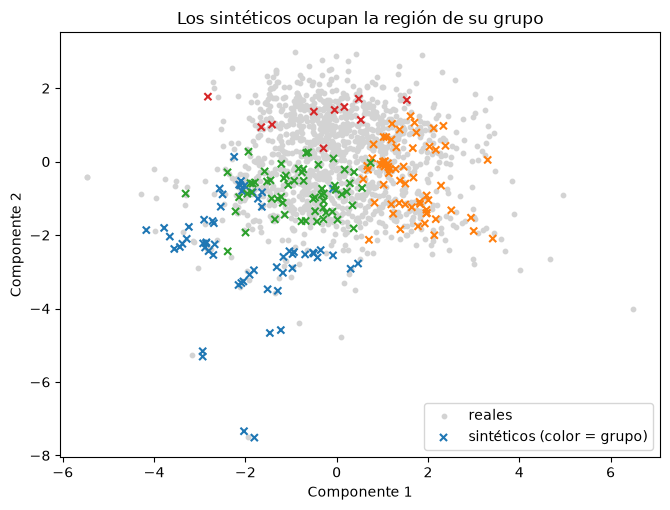

In [171]:
# Los sintéticos sobre el mismo plano PCA de los pacientes reales
Ps = pca.transform(Zs)
colores = plt.cm.tab10(sinteticos["cluster"].to_numpy().astype(int))

fig, ax = plt.subplots(figsize=(6.8, 5.2))
ax.scatter(Z2[:, 0], Z2[:, 1], c="lightgray", s=10, label="reales")
ax.scatter(Ps[:, 0], Ps[:, 1], c=colores, s=26, marker="x", label="sintéticos (color = grupo)")
ax.set_xlabel("Componente 1")
ax.set_ylabel("Componente 2")
ax.set_title("Los sintéticos ocupan la región de su grupo")
ax.legend()
plt.tight_layout()
plt.show()

In [172]:
def verificar(texto, condicion, extra=""):
    print(("OK  " if condicion else "FALLA"), texto, extra)

verificar("al menos 2 grupos", sinteticos["cluster"].nunique() >= 2)
verificar("todo grupo real tiene sintéticos (n_sinteticos > 0)", set(res_c["cluster"]) <= set(sinteticos["cluster"]))
verificar("todos marcados origen = sintetico", (sinteticos["origen"] == "sintetico").all())
verificar("ningún sintético fuera del rango real", fuera == 0, f"({fuera})")
verificar("más del 85 % se reconoce en su grupo", cons_global > 0.85, f"({cons_global:.1%})")

OK   al menos 2 grupos 
OK   todo grupo real tiene sintéticos (n_sinteticos > 0) 
OK   todos marcados origen = sintetico 
OK   ningún sintético fuera del rango real (0)
OK   más del 85 % se reconoce en su grupo (96.8%)


### Controles de calidad de los sintéticos

Los sintéticos se generan dentro de cada grupo: un paciente real del grupo, con un poco de ruido (20 % de la desviación estándar) y respetando el mínimo y el máximo de ese grupo. Antes de darlos por buenos se revisan cuatro cosas:

1. **¿Se reconocen en su grupo?** Se pasan por el **mismo** preprocesamiento y el mismo K-means. Si nacieron en el grupo 1, el modelo debería asignarlos al grupo 1. Es una prueba optimista, porque son copias de reales con poco ruido.
2. **¿Están dentro del rango clínico?** Ninguno debe salirse del rango de su grupo. Se cumple por construcción, porque se recorta a ese rango, así que esta prueba verifica la implementación y no la calidad.
3. **¿Se parecen a los reales?** Se comparan las medias por grupo.
4. **¿Ocupan la región de su grupo?** Se dibujan sobre el mismo PCA.

**Tres reglas que no se negocian:**
1. Un sintético **no agrega información nueva**: reproduce la que ya tenían los reales de su grupo.
2. **Nunca** se evalúa un modelo con sintéticos ni se presenta como validación clínica.
3. Todo sintético queda **marcado** (`origen = sintetico`) y **ligado a su cluster**.

### Resultados de los controles

**1. Reconocimiento en su grupo**

| Grupo | Sintéticos reconocidos |
|---|---|
| 0 | 90,0 % |
| 1 | 100 % |
| 2 | 100 % |
| 3 | 100 % |
| **Global** | **96,8 %** |

Los grupos 1, 2 y 3 se reconocen siempre. El grupo 0 es el más fronterizo: 1 de cada 10 sintéticos cae en otro grupo. Es también el grupo con la saturación más baja (88), y por eso el más expuesto a solaparse con otro.

**2. Rango clínico.** Valores sintéticos fuera del rango real: **0**. Se esperaba por construcción.

**3. Medias reales vs. sintéticas**

| Grupo | Edad (real / sint.) | SBP | HR | Saturación | Dolor (NRS) |
|---|---|---|---|---|---|
| 0 | 68,3 / 73,5 | 116,5 / 112,3 | 94,4 / 91,8 | 88,2 / 89,4 | 0,8 / 0,8 |
| 1 | 57,1 / 61,1 | 166,7 / 166,4 | 87,3 / 87,2 | 97,8 / 97,9 | 2,4 / 2,1 |
| 2 | 58,6 / 57,9 | 122,4 / 119,5 | 83,2 / 85,3 | 97,6 / 98,1 | 0,0 / 0,0 |
| 3 | 48,9 / 46,2 | 123,6 / 122,7 | 81,9 / 82,8 | 97,7 / 98,0 | 4,1 / 4,5 |

Los sintéticos conservan el perfil de cada grupo: la SBP alta del grupo 1, el dolor 0 del grupo 2 y el dolor más alto del grupo 3. Las diferencias más grandes son la edad en el grupo 0 (+5,2 años) y en el grupo 1 (+4,0 años), y la SBP en el grupo 0 (−4,2).

**Nota sobre el grupo 0.** La edad media de los sintéticos (73,5 años) es mayor que la de los reales (68,3). Con 60 sintéticos remuestreados, la media puede desviarse unos 2,2 años por azar, y esta diferencia (5,2 años) equivale a unas 2,3 veces esa cifra. Es poco frecuente para una sola comparación (alrededor del 1 % de las generaciones, con una aproximación normal), pero no inusual entre las 20 comparaciones realizadas (4 grupos × 5 variables). Se verificó que el generador no tiene sesgo: el promedio de 500 generaciones con distintas semillas es 68,4 años (real: 68,3). Las diferencias vienen de *cuáles* reales se remuestrearon y no de un error del generador. Los sintéticos nunca se usan para entrenar ni evaluar el modelo, así que esta diferencia no afecta las métricas.

**4. Región del grupo en el PCA.** Los sintéticos caen dentro de la nube de los reales y se separan por color de forma coherente. Los del grupo 0 (azul) se extienden hacia abajo, y algunos puntos del componente 2 (entre −5 y −7,5) tienen pocos reales cerca. Esto concuerda con que el grupo 0 sea el menos nítido en el control 1.

### Conclusión

Los sintéticos conservan el perfil de su grupo y se reconocen en él en el 96,8 % de los casos. El grupo 0 es el menos nítido (90 %), y su diferencia de edad (73,5 vs. 68,3) es la mayor de la tabla. Como solo reproducen lo que ya tenían los reales, no agregan información nueva, y por eso quedan fuera del entrenamiento y la evaluación del modelo.

---
# Conclusión final: dos modelos, dos trabajos

El sistema usa **un modelo de cada familia**, porque cada una resuelve algo que la otra no puede:

| Necesidad | Quién la resuelve | Por qué la otra no puede |
|---|---|---|
| Decir si un paciente nuevo es urgente (R10, R20) | **Supervisado** | Los grupos no tienen etiqueta de urgencia |
| Describir perfiles de pacientes y generar sintéticos coherentes dentro de cada grupo (R07) | **No supervisado** | El clasificador solo da una probabilidad |
| Saber **dónde se equivoca** el modelo (lo pide R07) | **Las dos juntas** | Se necesitan los grupos y las predicciones |

Hay una precisión importante sobre el flujo: los grupos se forman **sin usar la etiqueta**; solo después se calcula el porcentaje de urgentes por grupo para interpretarlos.

Los pacientes sintéticos **nunca** se usan para entrenar ni evaluar. Sirven para poblar el sistema; no mejoran el AUC.

In [173]:
print("=" * 74)
print("CONCLUSIÓN FINAL")
print("=" * 74)

r_ = tabla_sup.loc[elegido_sup]
resumen_final = pd.DataFrame([
    {"Tarea": "Predecir urgencia (supervisado)", "Modelo elegido": elegido_sup,
     "Evidencia": f"AUC_cv {r_['AUC_cv']:.3f} ± {r_['desviacion']:.3f}; AUC prueba {roc_auc_score(y_test, proba):.3f}; "
                  f"{len(empatados)} modelo(s) empatado(s) con el mejor"},
    {"Tarea": "Agrupar pacientes (no supervisado)", "Modelo elegido": elegido_nosup,
     "Evidencia": f"k = {K_ELEGIDO}; silueta {tabla_nosup.loc[elegido_nosup, 'silueta']:.3f}; "
                  f"Davies-Bouldin {tabla_nosup.loc[elegido_nosup, 'davies_bouldin']:.2f}"},
]).set_index("Tarea")
print(resumen_final.to_string())



print("\nLimitaciones que se declaran:")
for l_ in ["No se usa el motivo de consulta.",
           "Saturación vacía en el 55 % de los registros (se imputa con la mediana).",
           "Solo dos hospitales de Corea: no se sabe si generaliza a Colombia.",
           "La prueba tiene 254 pacientes: las cifras cambian algo con otra partición.",
           "El modelo aprendió «urgente» (KTAS 1-3), no «crítico».",
           "La silueta es baja: los grupos son segmentos, no categorías naturales."]:
    print("  -", l_)

CONCLUSIÓN FINAL
                                   Modelo elegido                                                                     Evidencia
Tarea                                                                                                                          
Predecir urgencia (supervisado)           XGBoost  AUC_cv 0.833 ± 0.007; AUC prueba 0.765; 2 modelo(s) empatado(s) con el mejor
Agrupar pacientes (no supervisado)        K-means                                     k = 4; silueta 0.122; Davies-Bouldin 2.00

Limitaciones que se declaran:
  - No se usa el motivo de consulta.
  - Saturación vacía en el 55 % de los registros (se imputa con la mediana).
  - Solo dos hospitales de Corea: no se sabe si generaliza a Colombia.
  - La prueba tiene 254 pacientes: las cifras cambian algo con otra partición.
  - El modelo aprendió «urgente» (KTAS 1-3), no «crítico».
  - La silueta es baja: los grupos son segmentos, no categorías naturales.
